## **Nama : Putri Meylani**
## **Nim : H061241088**
## **Tugas Perencanaan Prompt AI untuk Bidang Geofisika**


## Prompt 1 — QC dan Interpretasi Awal VES Geolistrik Schlumberger

### [R] Role
Bertindaklah sebagai reviewer QC data geolistrik dengan latar belakang geofisika hidrogeologi, terbiasa memeriksa data lapangan VES sebelum masuk tahap inversi. Fokus kerja: (1) konsistensi geometri elektroda AB/2 dan MN/2 terhadap asumsi konfigurasi Schlumberger, (2) kewajaran nilai arus, tegangan, dan resistivitas semu terhadap rentang fisik yang masuk akal, (3) traceability setiap angka ρa ke rumus faktor geometri yang dipakai, dan (4) pemisahan tegas antara "data yang diverifikasi", "data yang diasumsikan", dan "data yang tidak dapat diperiksa". Kamu tidak berperan sebagai interpreter geologi atau juru bor pada tahap ini — keputusan soal lapisan akuifer dan lokasi bor bukan bagian dari peranmu.

### [T] Task
Periksa data sounding `data/raw/ves_line01.csv` untuk konsistensi AB/2, MN/2, arus, dan tegangan, hitung ulang resistivitas semu (ρa) dari `ΔV/I × faktor geometri`, lalu tandai titik yang menyimpang dari kurva sounding yang monoton wajar. Jangan menjalankan inversi otomatis atau menetapkan model lapisan akhir.

### [C] Context
Sounding dilakukan di `{{lokasi}}` untuk eksplorasi air tanah dangkal. Hasil QC dipakai tim lapangan untuk memutuskan apakah titik perlu diulang sebelum interpretasi litologi dan rekomendasi bor. Hasil tahap ini bukan penentuan lapisan akuifer final.

### [I] Input
- `data/raw/ves_line01.csv`: kolom `ab_2_m`, `mn_2_m`, `i_ma`, `dv_mv`, `rho_a_ohm_m` (bila sudah dihitung sumber). Konfigurasi: Schlumberger. Sumber alat: `{{merek/model resistivitymeter}}`.
- `data/raw/ves_coordinates.csv`: `point_id`, `lat`, `lon`, `elev_m`, CRS `{{EPSG:...}}`.
- Jangan memakai: nilai resistivitas dari laporan pihak lain yang tidak tercantum di file sumber.

### [K] Constraints
- Jangan mengubah `data/raw/`; jangan menghapus baris pengukuran.
- Jangan menjalankan inversi 1D/2D, memilih jumlah lapisan, atau menetapkan model geologi.
- Gunakan hanya Python standard library, NumPy, dan pandas; tanpa akses jaringan.
- Ambang kewajaran ρa (mis. lompatan tajam antar titik berdekatan) harus dinyatakan sebagai `{{ambang %}}`, bukan ditetapkan sendiri tanpa disebut.
- Jika AB/2 dan MN/2 tidak konsisten dengan asumsi Schlumberger (MN ≪ AB), tandai "tidak terverifikasi" dan berhenti pada titik itu.

### [O] Output (rencana teks)
- `results/ves/ves_line01_qc.md`: jumlah titik sounding, rentang AB/2, jumlah titik dengan flag, ringkasan bentuk kurva per segmen.
- `results/ves/ves_line01_flags.csv`: `point_id`, `flag_type`, `value`, `threshold`, `note`.
- `results/ves/rho_a_recomputed.csv`: `point_id`, `rho_a_input`, `rho_a_recomputed`, `selisih_persen`.
- `results/ves/summary.json`: `n_points`, `n_flagged`, `n_non_monotonic`.

### [Q] Quality criteria
- Jumlah baris `flags.csv` + baris tak bermasalah = jumlah titik input.
- Setiap flag memuat nilai, ambang, dan alasan.
- `rho_a_recomputed` dan `rho_a_input` dibandingkan secara eksplisit, bukan diasumsikan sama.
- Raw data tidak berubah.

### [V] Optional verification
- Check: hitung ulang faktor geometri Schlumberger `π[(AB/2)² − (MN/2)²]/MN` untuk 5 titik acak. Expected: selisih dengan `rho_a_recomputed` di bawah `{{toleransi}}`%. Jika gagal: tandai rumus faktor geometri tidak konsisten.
- Check: SHA-256 `ves_line01.csv` sebelum dan sesudah prosedur. Expected: identik. Jika gagal: hentikan dan laporkan.

```
Input  : data/raw/ves_line01.csv (ab_2_m, mn_2_m, i_ma, dv_mv, rho_a_ohm_m) + data/raw/ves_coordinates.csv
Model  : Schlumberger, K = pi[(AB/2)^2 - (MN/2)^2]/MN ; rho_a = K x dV/I  (TANPA inversi / model lapisan)
Proses : cek geometri MN << AB -> hitung ulang rho_a -> flag lompatan & non-monotonik -> ringkas kurva per segmen
Output : results/ves/ ves_line01_qc.md, ves_line01_flags.csv, rho_a_recomputed.csv, summary.json
Cek    : faktor geometri 5 titik acak + SHA-256 raw data sebelum/sesudah
```

In [6]:
import os
import json
import math
import random
import hashlib
import numpy as np
import pandas as pd

np.random.seed(21)
random.seed(21)

# PARAMETER (isian placeholder {{...}} pada prompt)
lokasi = "Daerah Contoh (isi sesuai lokasi sounding)"     # {{lokasi}}
alat = "Resistivitymeter (isi merek/model)"                # {{merek/model resistivitymeter}}
epsg = "EPSG:4326"                                          # {{EPSG:...}} untuk lat/lon pada ves_coordinates.csv
ambang_lompatan_persen = 40.0    # {{ambang %}} lompatan rho_a antar titik berdekatan
ambang_balik_persen = 10.0       # amplitudo minimum tiap sisi agar balik arah dianggap non-monotonik
toleransi_persen = 1.0           # {{toleransi}} selisih rho_a_input vs rho_a_recomputed
rasio_mn_ab_maks = 0.2           # asumsi Schlumberger (MN << AB): MN/AB <= 1/5
rho_min_fisik = 1.0              # ohm.m, batas bawah rentang kewajaran
rho_max_fisik = 5000.0           # ohm.m, batas atas rentang kewajaran

path_raw = "data/raw/ves_line01.csv"
path_koord = "data/raw/ves_coordinates.csv"
folder_out = "results/ves"
os.makedirs("data/raw", exist_ok=True)
os.makedirs(folder_out, exist_ok=True)


# PEMBANGKIT DATA CONTOH (dilewati bila file data lapangan sudah ada)
if not os.path.exists(path_raw):
    ab2_c = np.array([2.5, 3, 4, 5, 6, 8, 10, 15, 20, 25, 30, 40, 50, 65, 80, 100, 130, 150], dtype=float)
    mn2_c = np.where(ab2_c <= 10, 0.5, np.where(ab2_c <= 25, 2.5, 5.0))
    i_c = np.array([20, 20, 20, 20, 20, 50, 50, 50, 100, 100, 100, 150, 150, 200, 200, 200, 300, 300], dtype=float)
    ctrl_x = np.log10([2.5, 6, 15, 40, 100, 150])
    ctrl_y = np.log10([48, 40, 24, 30, 45, 58])
    rho_c = 10 ** np.interp(np.log10(ab2_c), ctrl_x, ctrl_y)
    K_c = np.pi * (ab2_c ** 2 - mn2_c ** 2) / (2 * mn2_c)
    dv_c = rho_c * i_c / K_c * np.exp(np.random.normal(0, 0.015, len(ab2_c)))
    dv_c[11] = dv_c[11] * 1.55                  # outlier buatan pada AB/2 = 40 m
    rho_src = K_c * dv_c / i_c
    rho_src[6] = rho_src[6] * 1.08              # selisih hitung dari sumber (buatan) pada AB/2 = 10 m
    pd.DataFrame({"ab_2_m": ab2_c, "mn_2_m": mn2_c, "i_ma": i_c,
                  "dv_mv": dv_c.round(3), "rho_a_ohm_m": rho_src.round(2)}).to_csv(path_raw, index=False)
if not os.path.exists(path_koord):
    pd.DataFrame({"point_id": ["VES-01"], "lat": [-4.5000], "lon": [119.9000], "elev_m": [25.0]}).to_csv(path_koord, index=False)

# SHA-256 file input SEBELUM prosedur
with open(path_raw, "rb") as f_raw:
    sha_awal = hashlib.sha256(f_raw.read()).hexdigest()
with open(path_koord, "rb") as f_koord:
    sha_koord_awal = hashlib.sha256(f_koord.read()).hexdigest()

data = pd.read_csv(path_raw)
koord = pd.read_csv(path_koord)


# PEMERIKSAAN KECUKUPAN DATA (hentikan jika tidak memadai)
kolom_wajib = ["ab_2_m", "mn_2_m", "i_ma", "dv_mv"]
kurang = [k for k in kolom_wajib if k not in data.columns]
if len(kurang) > 0:
    raise SystemExit("Data tidak memadai: kolom berikut belum ada -> %s" % kurang)
kurang_k = [k for k in ["point_id", "lat", "lon", "elev_m"] if k not in koord.columns]
if len(kurang_k) > 0:
    raise SystemExit("ves_coordinates.csv tidak memadai: kolom belum ada -> %s" % kurang_k)
if len(data) < 5:
    raise SystemExit("Data terlalu sedikit (< 5 titik AB/2) untuk QC kurva sounding.")

for k in kolom_wajib:
    data[k] = pd.to_numeric(data[k], errors="coerce")        # hanya di memori, file mentah tidak diubah
ada_rho_input = "rho_a_ohm_m" in data.columns
data = data.sort_values("ab_2_m").reset_index(drop=True)
n = len(data)
data["point_id"] = ["T%02d" % (i + 1) for i in range(n)]      # id titik ukur (urutan AB/2 naik)

pid = data["point_id"].values
ab2 = data["ab_2_m"].values.astype(float)
mn2 = data["mn_2_m"].values.astype(float)
arus = data["i_ma"].values.astype(float)
dv = data["dv_mv"].values.astype(float)
if ada_rho_input:
    rho_in = pd.to_numeric(data["rho_a_ohm_m"], errors="coerce").values.astype(float)
else:
    rho_in = np.full(n, np.nan)

print("=== INFORMASI SURVEI ===")
print("Lokasi: %s | Alat: %s | Konfigurasi: Schlumberger" % (lokasi, alat))
for r in range(len(koord)):
    lat_k = koord["lat"].iloc[r]
    lon_k = koord["lon"].iloc[r]
    ok_koord = (-90 <= lat_k <= 90) and (-180 <= lon_k <= 180)
    print("Koordinat %s: lat %.4f, lon %.4f, elev %.1f m, CRS %s -> %s" % (
        koord["point_id"].iloc[r], lat_k, lon_k, koord["elev_m"].iloc[r], epsg,
        "wajar" if ok_koord else "DI LUAR RENTANG, periksa CRS/koordinat"))


# (1) KONSISTENSI GEOMETRI ELEKTRODA (asumsi Schlumberger: MN << AB)
flags = []
valid = np.ones(n, dtype=bool)
n_diproses = n
for i in range(n):
    if np.isnan(ab2[i]) or np.isnan(mn2[i]) or np.isnan(arus[i]) or np.isnan(dv[i]):
        flags.append({"point_id": pid[i], "flag_type": "data_kosong_atau_bukan_angka", "value": np.nan,
                      "threshold": np.nan, "note": "salah satu dari ab_2_m, mn_2_m, i_ma, dv_mv kosong/bukan angka"})
        valid[i] = False
        continue
    if ab2[i] <= 0 or mn2[i] <= 0 or arus[i] <= 0:
        flags.append({"point_id": pid[i], "flag_type": "nilai_tidak_fisik", "value": float(min(ab2[i], mn2[i], arus[i])),
                      "threshold": 0.0, "note": "AB/2, MN/2, atau arus <= 0"})
        valid[i] = False
        continue
    rasio = mn2[i] / ab2[i]
    if rasio > rasio_mn_ab_maks + 1e-9:
        flags.append({"point_id": pid[i], "flag_type": "tidak_terverifikasi_schlumberger", "value": round(float(rasio), 4),
                      "threshold": rasio_mn_ab_maks,
                      "note": "MN/2 terhadap AB/2 tidak memenuhi MN << AB; pemeriksaan dihentikan pada titik ini"})
        valid[i] = False
        n_diproses = i
        break

if n_diproses < n:
    for j in range(n_diproses + 1, n):
        flags.append({"point_id": pid[j], "flag_type": "tidak_diproses", "value": np.nan, "threshold": np.nan,
                      "note": "titik setelah titik %s yang tidak terverifikasi Schlumberger" % pid[n_diproses]})
        valid[j] = False
    print("PERINGATAN: geometri tidak sesuai Schlumberger pada %s -> TIDAK TERVERIFIKASI, proses dihentikan di titik ini." % pid[n_diproses])
else:
    print("Semua %d titik memenuhi asumsi Schlumberger (MN/AB <= %.2f)." % (n, rasio_mn_ab_maks))


# (2) HITUNG ULANG rho_a = (dV/I) x K,  K = pi[(AB/2)^2 - (MN/2)^2]/MN
K_geom = np.full(n, np.nan)
rho_re = np.full(n, np.nan)
for i in range(n_diproses):
    if valid[i]:
        K_geom[i] = np.pi * (ab2[i] ** 2 - mn2[i] ** 2) / (2 * mn2[i])      # MN = 2 x (MN/2)
        rho_re[i] = K_geom[i] * dv[i] / arus[i]                              # mV/mA = ohm

with np.errstate(divide="ignore", invalid="ignore"):
    selisih = (rho_re - rho_in) / rho_in * 100.0

for i in range(n_diproses):
    if not valid[i]:
        continue
    if rho_re[i] < rho_min_fisik or rho_re[i] > rho_max_fisik:
        flags.append({"point_id": pid[i], "flag_type": "rho_a_di_luar_rentang_fisik", "value": round(float(rho_re[i]), 2),
                      "threshold": rho_min_fisik if rho_re[i] < rho_min_fisik else rho_max_fisik,
                      "note": "rho_a di luar rentang %.0f-%.0f ohm.m" % (rho_min_fisik, rho_max_fisik)})
    if ada_rho_input and np.isfinite(selisih[i]) and abs(selisih[i]) > toleransi_persen:
        flags.append({"point_id": pid[i], "flag_type": "rho_a_beda_dari_input", "value": round(float(selisih[i]), 2),
                      "threshold": toleransi_persen,
                      "note": "rho_a hitung ulang berbeda dari kolom rho_a_ohm_m sumber; periksa rumus/faktor geometri sumber"})

# (3) KEWAJARAN KURVA: lompatan tajam dan balik arah (non-monotonik)
for i in range(1, n_diproses):
    if valid[i] and valid[i - 1] and np.isfinite(rho_re[i]) and np.isfinite(rho_re[i - 1]):
        lompat = (rho_re[i] - rho_re[i - 1]) / rho_re[i - 1] * 100.0
        if abs(lompat) > ambang_lompatan_persen:
            catatan = "lompatan rho_a terhadap titik sebelumnya (%s)" % pid[i - 1]
            if mn2[i] != mn2[i - 1]:
                catatan = catatan + "; terjadi pada pergantian MN/2"
            flags.append({"point_id": pid[i], "flag_type": "lompatan_tajam", "value": round(float(lompat), 2),
                          "threshold": ambang_lompatan_persen, "note": catatan})

for i in range(1, n_diproses - 1):
    if valid[i - 1] and valid[i] and valid[i + 1]:
        d1 = (rho_re[i] - rho_re[i - 1]) / rho_re[i - 1] * 100.0
        d2 = (rho_re[i + 1] - rho_re[i]) / rho_re[i] * 100.0
        if d1 * d2 < 0 and abs(d1) > ambang_balik_persen and abs(d2) > ambang_balik_persen:
            flags.append({"point_id": pid[i], "flag_type": "non_monotonik_balik_arah",
                          "value": round(float(max(abs(d1), abs(d2))), 2), "threshold": ambang_balik_persen,
                          "note": "rho_a naik/turun lalu berbalik arah tajam (%.1f%% lalu %.1f%%) terhadap tetangga" % (d1, d2)})

flags_df = pd.DataFrame(flags, columns=["point_id", "flag_type", "value", "threshold", "note"])
titik_flag = sorted(set(flags_df["point_id"]))
n_flagged = len(titik_flag)
n_ok = n - n_flagged
n_non_monotonic = int((flags_df["flag_type"] == "non_monotonik_balik_arah").sum())
bermasalah = np.array([p in titik_flag for p in pid])


# (4) RINGKASAN BENTUK KURVA PER SEGMEN (segmen = blok MN/2 yang sama berurutan)
ringkasan_segmen = []
if n_diproses > 0:
    awal = 0
    for i in range(1, n_diproses + 1):
        if i == n_diproses or mn2[i] != mn2[awal]:
            idx = list(range(awal, i))
            idx_ok = [j for j in idx if valid[j] and (not bermasalah[j])]
            teks = "Segmen MN/2 = %.2f m, AB/2 %.1f-%.1f m (%d titik, %d tanpa flag): " % (
                mn2[awal], ab2[idx[0]], ab2[idx[-1]], len(idx), len(idx_ok))
            if len(idx_ok) >= 3:
                kemiringan = np.polyfit(np.log10(ab2[idx_ok]), np.log10(rho_re[idx_ok]), 1)[0]
                if kemiringan > 0.1:
                    bentuk = "rho_a cenderung NAIK"
                elif kemiringan < -0.1:
                    bentuk = "rho_a cenderung TURUN"
                else:
                    bentuk = "rho_a relatif DATAR"
                teks = teks + "%s (kemiringan log-log %.2f), rho_a %.1f-%.1f ohm.m" % (
                    bentuk, kemiringan, rho_re[idx_ok].min(), rho_re[idx_ok].max())
            else:
                teks = teks + "titik tanpa flag < 3, bentuk kurva tidak dapat dinilai"
            ringkasan_segmen.append(teks)
            awal = i


# OUTPUT
tabel_re = pd.DataFrame({"point_id": pid, "rho_a_input": rho_in, "rho_a_recomputed": rho_re.round(3),
                         "selisih_persen": np.round(selisih, 3)})
tabel_re.to_csv(os.path.join(folder_out, "rho_a_recomputed.csv"), index=False)
flags_df.to_csv(os.path.join(folder_out, "ves_line01_flags.csv"), index=False)

ringkasan = {"n_points": int(n), "n_flagged": int(n_flagged), "n_non_monotonic": int(n_non_monotonic)}
with open(os.path.join(folder_out, "summary.json"), "w") as f_sum:
    json.dump(ringkasan, f_sum, indent=2)

ab2_valid = ab2[np.isfinite(ab2)]
baris_md = ["# QC Data VES Schlumberger - ves_line01", "",
            "- Lokasi: %s | Alat: %s | CRS koordinat: %s" % (lokasi, alat, epsg),
            "- Jumlah titik sounding: %d (diproses penuh: %d)" % (n, n_diproses),
            "- Rentang AB/2: %.1f - %.1f m" % (ab2_valid.min(), ab2_valid.max()),
            "- Jumlah titik dengan flag: %d | titik tanpa masalah: %d" % (n_flagged, n_ok),
            "- Titik non-monotonik (balik arah tajam): %d" % n_non_monotonic,
            "- Ambang: lompatan %.0f%%, balik arah %.0f%%, toleransi rho_a %.1f%%, MN/AB <= %.2f"
            % (ambang_lompatan_persen, ambang_balik_persen, toleransi_persen, rasio_mn_ab_maks), "",
            "## Ringkasan bentuk kurva per segmen"] + ["- " + t for t in ringkasan_segmen] + ["", "## Titik ber-flag"]
if n_flagged == 0:
    baris_md.append("- tidak ada")
for r in range(len(flags_df)):
    baris_md.append("- %s | %s | nilai %s | ambang %s | %s" % (
        flags_df["point_id"].iloc[r], flags_df["flag_type"].iloc[r], flags_df["value"].iloc[r],
        flags_df["threshold"].iloc[r], flags_df["note"].iloc[r]))
baris_md += ["", "## Batasan tahap ini",
             "- Tidak ada inversi 1D/2D, penentuan jumlah lapisan, atau model geologi pada tahap QC ini.",
             "- Keputusan lapisan akuifer dan lokasi bor BUKAN bagian dari laporan ini."]
with open(os.path.join(folder_out, "ves_line01_qc.md"), "w", encoding="utf-8") as f_md:
    f_md.write("\n".join(baris_md))

print("\n=== HASIL QC ===")
print("Jumlah titik: %d | rentang AB/2: %.1f - %.1f m" % (n, ab2_valid.min(), ab2_valid.max()))
print("Titik ber-flag: %d | titik non-monotonik: %d" % (n_flagged, n_non_monotonic))
print("\nRingkasan bentuk kurva per segmen:")
for t in ringkasan_segmen:
    print(" -", t)
print("\n=== TABEL flags.csv ===")
print(flags_df.to_string(index=False))
print("\n=== TABEL rho_a_recomputed.csv ===")
print(tabel_re.to_string(index=False))


# KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Titik unik di flags + titik tanpa masalah = %d + %d = %d (jumlah input %d) -> %s" % (
    n_flagged, n_ok, n_flagged + n_ok, n, "OK" if n_flagged + n_ok == n else "TIDAK SAMA"))
print("Setiap flag memuat nilai, ambang, dan alasan: %s" % (
    "OK" if flags_df["note"].notna().all() else "ADA FLAG TANPA ALASAN"))
print("rho_a_recomputed dibandingkan eksplisit dengan rho_a_input: %s" % ("OK (kolom selisih_persen)" if ada_rho_input else "rho_a_input tidak tersedia"))


# VERIFIKASI (opsional)
print("\n=== VERIFIKASI ===")
kandidat = [i for i in range(n_diproses) if valid[i]]
pilih = random.sample(kandidat, min(5, len(kandidat)))
gagal = 0
for i in sorted(pilih):
    AB = 2 * ab2[i]
    MN = 2 * mn2[i]
    K_cek = math.pi * ((AB / 2) ** 2 - (MN / 2) ** 2) / MN
    rho_cek = K_cek * dv[i] / arus[i]
    beda = abs(rho_cek - rho_re[i]) / rho_re[i] * 100.0
    status = "OK" if beda < toleransi_persen else "TIDAK KONSISTEN"
    if beda >= toleransi_persen:
        gagal = gagal + 1
    print("%s: K = %.3f m, rho_a cek = %.3f vs recomputed = %.3f ohm.m, selisih %.4f%% -> %s" % (
        pid[i], K_cek, rho_cek, rho_re[i], beda, status))
if gagal > 0:
    print("-> Rumus faktor geometri tidak konsisten pada %d titik: TANDAI dan periksa." % gagal)

with open(path_raw, "rb") as f_raw2:
    sha_akhir = hashlib.sha256(f_raw2.read()).hexdigest()
with open(path_koord, "rb") as f_koord2:
    sha_koord_akhir = hashlib.sha256(f_koord2.read()).hexdigest()
print("SHA-256 ves_line01.csv sebelum : %s" % sha_awal)
print("SHA-256 ves_line01.csv sesudah : %s" % sha_akhir)
if sha_awal != sha_akhir or sha_koord_awal != sha_koord_akhir:
    raise SystemExit("Raw data BERUBAH selama prosedur. Hentikan dan laporkan.")
print("Raw data tidak berubah (SHA-256 identik).")
print("\nFile keluaran ditulis ke folder:", folder_out)
print(sorted(os.listdir(folder_out)))


=== INFORMASI SURVEI ===
Lokasi: Daerah Contoh (isi sesuai lokasi sounding) | Alat: Resistivitymeter (isi merek/model) | Konfigurasi: Schlumberger
Koordinat VES-01: lat -4.5000, lon 119.9000, elev 25.0 m, CRS EPSG:4326 -> wajar
Semua 18 titik memenuhi asumsi Schlumberger (MN/AB <= 0.20).

=== HASIL QC ===
Jumlah titik: 18 | rentang AB/2: 2.5 - 150.0 m
Titik ber-flag: 2 | titik non-monotonik: 1

Ringkasan bentuk kurva per segmen:
 - Segmen MN/2 = 0.50 m, AB/2 2.5-10.0 m (7 titik, 6 tanpa flag): rho_a cenderung TURUN (kemiringan log-log -0.29), rho_a 33.2-48.0 ohm.m
 - Segmen MN/2 = 2.50 m, AB/2 15.0-25.0 m (3 titik, 3 tanpa flag): rho_a cenderung NAIK (kemiringan log-log 0.24), rho_a 23.9-27.0 ohm.m
 - Segmen MN/2 = 5.00 m, AB/2 30.0-150.0 m (8 titik, 7 tanpa flag): rho_a cenderung NAIK (kemiringan log-log 0.45), rho_a 27.8-58.2 ohm.m

=== TABEL flags.csv ===
point_id                flag_type  value  threshold                                                                              

---

## Prompt 2 — QC Inversi ERT 2D untuk Kandidat Bidang Gelincir

### [R] Role
Bertindaklah sebagai reviewer QC hasil inversi resistivitas 2D dengan latar belakang geofisika geoteknik, terbiasa menilai keluaran software inversi (bukan menjalankannya) untuk keperluan mitigasi bencana. Fokus kerja: (1) menilai kualitas fit inversi melalui RMS error dan jumlah iterasi, bukan asumsi bahwa RMS rendah berarti model benar secara geologi, (2) memeriksa konsistensi satuan resistivitas, kedalaman, dan jarak sepanjang lintasan, (3) memisahkan secara eksplisit kalimat fakta terukur (nilai resistivitas, koordinat, RMS) dari kalimat dugaan geologi (litologi, bidang gelincir), dan (4) menahan diri dari membuat kesimpulan rekayasa seperti faktor keamanan lereng, karena itu di luar kewenangan geofisikawan dan memerlukan analisis geoteknik terpisah.

### [T] Task
Periksa file hasil inversi `data/raw/ert_line02_inversion.csv` untuk RMS error, sebaran resistivitas per segmen jarak dan kedalaman, lalu tandai segmen dengan resistivitas rendah yang berdekatan dengan permukaan sebagai kandidat zona jenuh air. Jangan menyimpulkan bidang gelincir atau faktor keamanan lereng.

### [C] Context
Lereng di `{{lokasi}}` mengalami retakan tanah setelah hujan lebat. Hasil dipakai tim mitigasi bencana daerah sebagai informasi awal untuk memutuskan survei lanjutan (bor, inklinometer), bukan sebagai analisis stabilitas lereng final.

### [I] Input
- `data/raw/ert_line02_inversion.csv`: `x_m`, `z_m` (kedalaman, m), `resistivity_ohm_m`, `sensitivity` (bila ada).
- `data/raw/ert_line02_meta.json`: konfigurasi (`Wenner-Schlumberger`), spasi elektroda `{{m}}`, panjang lintasan `{{m}}`, RMS error inversi `{{%}}`, jumlah iterasi.
- Ambang resistivitas rendah yang dianggap dugaan zona jenuh: `{{ohm·m}}`.

### [K] Constraints
- Jangan mengubah `data/raw/`; jangan menjalankan ulang inversi atau mengubah parameter regularisasi.
- Bedakan fakta (nilai resistivitas dan RMS) dari dugaan (litologi, bidang gelincir); tulis dugaan sebagai hipotesis eksplisit.
- Jika RMS error di atas `{{ambang %}}`, beri peringatan keandalan model pada laporan, jangan menyembunyikannya.
- Software: Python, NumPy, pandas, matplotlib yang tersedia; tanpa jaringan.
- Jangan menetapkan faktor keamanan lereng dalam bentuk apa pun.

### [O] Output (rencana teks)
- `results/ert/ert_line02_qc.md`: penilaian kualitas inversi, jumlah segmen, ringkasan RMS.
- `results/ert/zona_kandidat.csv`: `x_m`, `z_top_m`, `z_bottom_m`, `resistivity_ohm_m`, `kategori` (rendah/sedang/tinggi), `catatan_dugaan`.
- `results/ert/run_config.json`: ambang resistivitas, konfigurasi elektroda, RMS error, versi package.
- `results/ert/rekomendasi_lanjutan.md`: daftar segmen prioritas untuk bor/inklinometer beserta alasan.

### [Q] Quality criteria
- Setiap segmen kandidat memuat koordinat x, rentang kedalaman, dan nilai resistivitas yang mendasarinya.
- Kalimat dugaan geologi ditulis terpisah dari kalimat fakta terukur.
- RMS error dan keterbatasannya dinyatakan eksplisit di laporan.
- Tidak ada klaim faktor keamanan atau probabilitas longsor.

### [V] Optional verification
- Check: bandingkan jumlah segmen berkategori "rendah" dengan histogram resistivitas mentah. Expected: konsisten dengan ambang yang dinyatakan. Jika gagal: tandai kategori tidak konsisten.
- Check: SHA-256 file input sebelum dan sesudah. Expected: identik. Jika gagal: hentikan dan laporkan.

```
Input  : data/raw/ert_line02_inversion.csv (x_m, z_m, resistivity_ohm_m, sensitivity) + ert_line02_meta.json
Model  : TANPA inversi ulang; kategori resistivitas rendah/sedang/tinggi per segmen vertikal
Proses : cek RMS -> kategori -> segmen per kolom x -> kandidat zona jenuh dangkal (dugaan) -> zona prioritas
Output : results/ert/ ert_line02_qc.md, zona_kandidat.csv, run_config.json, rekomendasi_lanjutan.md
Cek    : jumlah segmen 'rendah' vs histogram mentah + SHA-256 file input
```

Lokasi: Lereng Contoh (isi sesuai lokasi)
Konfigurasi: Wenner-Schlumberger | spasi elektroda: 5.0 m | panjang lintasan: 200.0 m
Inversi: iterasi 5 | RMS error 8.4 %
Grid: 41 kolom x 20 baris (dx = 5.0 m, dz = 1.5 m)
RMS error 8.4% <= ambang 10.0%: kecocokan data-model dapat diterima (bukan jaminan solusi tunggal).

=== (1) SEBARAN RESISTIVITAS (FAKTA TERUKUR) ===
Resistivitas: min 30.4 | median 180.5 | maks 563.3 ohm.m
Ambang: rendah < 50 | sedang 50-300 | tinggi > 300 ohm.m
Kategori rendah:  147 sel (17.9% penampang)
Kategori sedang:  468 sel (57.1% penampang)
Kategori tinggi:  205 sel (25.0% penampang)

=== (2) SEGMEN ===
Jumlah segmen bermakna (>= 2 sel): 103 | segmen kandidat zona jenuh dangkal: 21
          jumlah_segmen  jumlah_sel
kategori                           
rendah               21         147
sedang               41         447
tinggi               41         205

=== (3) ZONA LATERAL KANDIDAT (diurutkan menurut luas sel) ===
Zona 1: x = 70-170 m (21 kolom), kedalaman 1

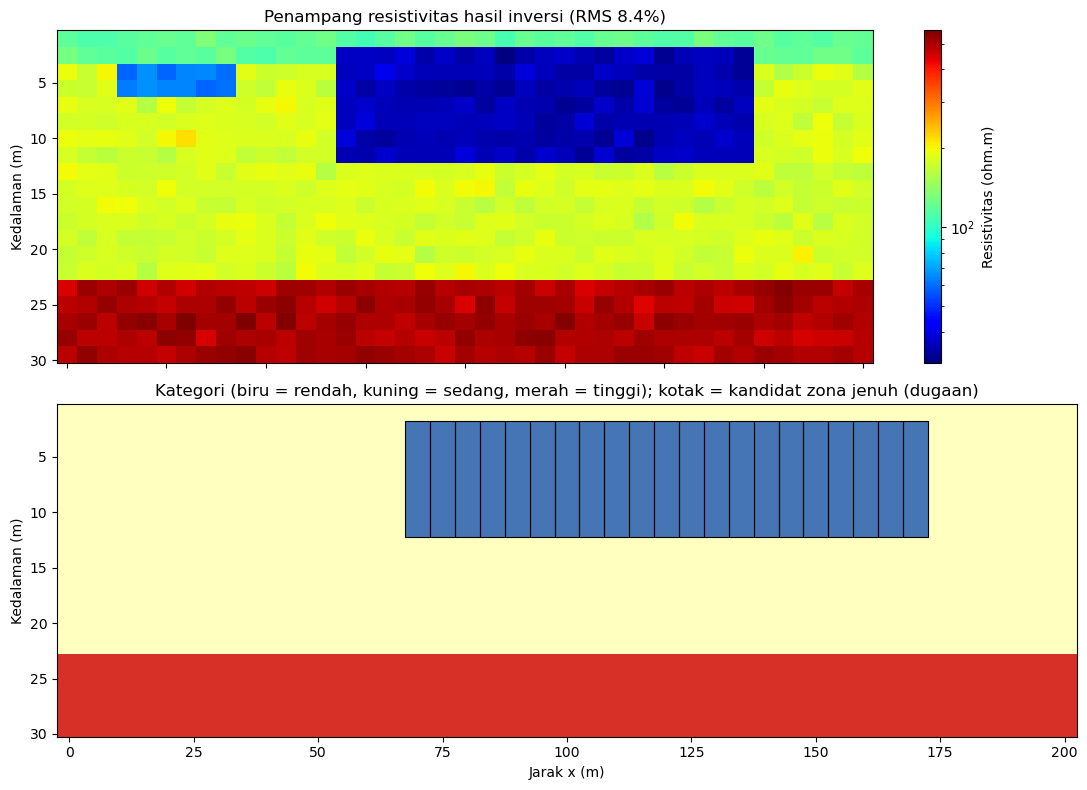

In [7]:
import os
import sys
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

np.random.seed(33)

# PARAMETER (isian placeholder {{...}} pada prompt)
lokasi = "Lereng Contoh (isi sesuai lokasi)"      # {{lokasi}}
ambang_rho_rendah = 50.0        # {{ohm.m}} resistivitas < nilai ini = dugaan zona jenuh air
ambang_rho_tinggi = 300.0       # resistivitas > nilai ini = kategori tinggi (sedang = di antaranya)
ambang_rms_persen = 10.0        # {{ambang %}} RMS error di atas nilai ini -> peringatan keandalan
batas_dekat_permukaan_m = 5.0   # segmen rendah dianggap dekat permukaan bila z_top <= nilai ini
min_sel_segmen = 2              # minimal jumlah sel vertikal agar segmen dianggap bermakna
ambang_sensitivitas = 0.05      # sensitivity < nilai ini = keandalan sel rendah (bila kolom ada)
n_prioritas = 3                 # jumlah zona prioritas pada rekomendasi lanjutan

path_inv = "data/raw/ert_line02_inversion.csv"
path_meta = "data/raw/ert_line02_meta.json"
folder_out = "results/ert"
os.makedirs("data/raw", exist_ok=True)
os.makedirs(folder_out, exist_ok=True)


# PEMBANGKIT DATA CONTOH (dilewati bila file data lapangan sudah ada)
if not os.path.exists(path_inv):
    xs_c = np.arange(0, 201, 5.0)
    zs_c = np.arange(1.0, 30.5, 1.5)
    Xc, Zc = np.meshgrid(xs_c, zs_c)
    rho_c = np.full(Xc.shape, 180.0)
    rho_c[Zc <= 3] = 120.0
    rho_c[(Xc >= 70) & (Xc <= 170) & (Zc >= 2.5) & (Zc <= 12)] = 35.0       # zona konduktif dangkal
    rho_c[(Xc >= 15) & (Xc <= 40) & (Zc > 3) & (Zc < 7)] = 62.0             # kantong resistivitas menengah-rendah
    rho_c[Zc > 22] = 500.0
    rho_c = rho_c * np.exp(np.random.normal(0, 0.05, rho_c.shape))
    sens_c = np.exp(-Zc / 9.0)
    pd.DataFrame({"x_m": Xc.ravel(), "z_m": Zc.ravel(), "resistivity_ohm_m": rho_c.ravel().round(2),
                  "sensitivity": sens_c.ravel().round(4)}).to_csv(path_inv, index=False)
if not os.path.exists(path_meta):
    meta_c = {"konfigurasi": "Wenner-Schlumberger", "spasi_elektroda_m": 5.0, "panjang_lintasan_m": 200.0,
              "rms_error_persen": 8.4, "jumlah_iterasi": 5}
    with open(path_meta, "w") as f_m:
        json.dump(meta_c, f_m, indent=2)

# SHA-256 file input SEBELUM prosedur
with open(path_inv, "rb") as f1:
    sha_inv_awal = hashlib.sha256(f1.read()).hexdigest()
with open(path_meta, "rb") as f2:
    sha_meta_awal = hashlib.sha256(f2.read()).hexdigest()

grid = pd.read_csv(path_inv)
with open(path_meta) as f_meta:
    meta = json.load(f_meta)


# PEMERIKSAAN KECUKUPAN DATA (hentikan jika tidak memadai)
for k in ["x_m", "z_m", "resistivity_ohm_m"]:
    if k not in grid.columns:
        raise SystemExit("Kolom '%s' tidak ada pada ert_line02_inversion.csv. Data tidak memadai." % k)
for k in ["konfigurasi", "spasi_elektroda_m", "panjang_lintasan_m", "rms_error_persen", "jumlah_iterasi"]:
    if k not in meta:
        raise SystemExit("Kunci '%s' tidak ada pada ert_line02_meta.json. Data tidak memadai." % k)
if grid["resistivity_ohm_m"].isna().any() or (grid["resistivity_ohm_m"] <= 0).any():
    raise SystemExit("Ada resistivitas kosong atau <= 0 pada file inversi. Periksa data sebelum QC.")

ada_sens = "sensitivity" in grid.columns
rho_tab = grid.pivot(index="z_m", columns="x_m", values="resistivity_ohm_m")
if rho_tab.isna().any().any():
    raise SystemExit("Grid inversi tidak lengkap (ada sel kosong pada pivot x-z).")
if len(rho_tab.columns) < 10 or len(rho_tab.index) < 5:
    raise SystemExit("Grid terlalu kecil untuk QC (minimal 10 kolom x 5 baris).")
x = rho_tab.columns.values.astype(float)
z = rho_tab.index.values.astype(float)
rho = rho_tab.values
if ada_sens:
    sens = grid.pivot(index="z_m", columns="x_m", values="sensitivity").loc[z, x].values
nz, nx = rho.shape
dx = x[1] - x[0]
dz = z[1] - z[0]

rms = float(meta["rms_error_persen"])
print("Lokasi: %s" % lokasi)
print("Konfigurasi: %s | spasi elektroda: %.1f m | panjang lintasan: %.1f m" % (
    meta["konfigurasi"], meta["spasi_elektroda_m"], meta["panjang_lintasan_m"]))
print("Inversi: iterasi %d | RMS error %.1f %%" % (meta["jumlah_iterasi"], rms))
print("Grid: %d kolom x %d baris (dx = %.1f m, dz = %.1f m)" % (nx, nz, dx, dz))
peringatan_rms = rms > ambang_rms_persen
if peringatan_rms:
    print("PERINGATAN: RMS error %.1f%% > ambang %.1f%% -> keandalan model rendah; seluruh hasil di bawah SANGAT tentatif." % (rms, ambang_rms_persen))
else:
    print("RMS error %.1f%% <= ambang %.1f%%: kecocokan data-model dapat diterima (bukan jaminan solusi tunggal)." % (rms, ambang_rms_persen))


# (1) KATEGORI RESISTIVITAS PER SEL
kategori = np.where(rho < ambang_rho_rendah, "rendah", np.where(rho > ambang_rho_tinggi, "tinggi", "sedang"))
print("\n=== (1) SEBARAN RESISTIVITAS (FAKTA TERUKUR) ===")
print("Resistivitas: min %.1f | median %.1f | maks %.1f ohm.m" % (rho.min(), np.median(rho), rho.max()))
print("Ambang: rendah < %.0f | sedang %.0f-%.0f | tinggi > %.0f ohm.m" % (
    ambang_rho_rendah, ambang_rho_rendah, ambang_rho_tinggi, ambang_rho_tinggi))
for nm in ["rendah", "sedang", "tinggi"]:
    print("Kategori %-6s: %4d sel (%.1f%% penampang)" % (nm, (kategori == nm).sum(), (kategori == nm).mean() * 100))


# (2) SEGMEN VERTIKAL PER KOLOM x (rangkaian sel berurutan dengan kategori sama)
segmen = []
for j in range(nx):
    i = 0
    while i < nz:
        k = i
        while k + 1 < nz and kategori[k + 1, j] == kategori[i, j]:
            k = k + 1
        n_sel = k - i + 1
        if n_sel >= min_sel_segmen:
            z_top = max(z[i] - dz / 2, 0.0)
            z_bottom = z[k] + dz / 2
            rho_seg = float(rho[i:k + 1, j].mean())
            kand = (kategori[i, j] == "rendah") and (z_top <= batas_dekat_permukaan_m)
            sens_seg = float(sens[i:k + 1, j].mean()) if ada_sens else np.nan
            if kand:
                catatan = "DUGAAN (hipotesis): kandidat zona jenuh air dangkal; resistivitas rendah juga bisa berasal dari lempung (air vs lempung belum dapat dibedakan)"
                if ada_sens and sens_seg < ambang_sensitivitas:
                    catatan = catatan + "; sensitivitas rendah (%.3f), keandalan berkurang" % sens_seg
            elif kategori[i, j] == "rendah":
                catatan = "resistivitas rendah tetapi z_top > %.1f m (tidak dekat permukaan); bukan kandidat" % batas_dekat_permukaan_m
            else:
                catatan = "-"
            segmen.append({"x_m": x[j], "z_top_m": round(z_top, 2), "z_bottom_m": round(z_bottom, 2),
                           "resistivity_ohm_m": round(rho_seg, 2), "kategori": kategori[i, j],
                           "catatan_dugaan": catatan, "n_sel": n_sel, "kandidat": kand, "sens": sens_seg})
        i = k + 1

seg_df = pd.DataFrame(segmen)
n_segmen = len(seg_df)
n_kand = int(seg_df["kandidat"].sum())
print("\n=== (2) SEGMEN ===")
print("Jumlah segmen bermakna (>= %d sel): %d | segmen kandidat zona jenuh dangkal: %d" % (min_sel_segmen, n_segmen, n_kand))
print(seg_df.groupby("kategori")["n_sel"].agg(["count", "sum"]).rename(columns={"count": "jumlah_segmen", "sum": "jumlah_sel"}).to_string())


# (3) ZONA LATERAL KANDIDAT (kolom kandidat yang bersambung di sepanjang x)
kand_df = seg_df[seg_df["kandidat"]].sort_values("x_m").reset_index(drop=True)
zona = []
if len(kand_df) > 0:
    awal = 0
    for r in range(1, len(kand_df) + 1):
        if r == len(kand_df) or kand_df["x_m"].iloc[r] - kand_df["x_m"].iloc[r - 1] > dx * 1.01:
            blok = kand_df.iloc[awal:r]
            zona.append({"x_awal": blok["x_m"].min(), "x_akhir": blok["x_m"].max(),
                         "z_top": blok["z_top_m"].min(), "z_bottom": blok["z_bottom_m"].max(),
                         "rho_rata": float(np.average(blok["resistivity_ohm_m"], weights=blok["n_sel"])),
                         "n_sel": int(blok["n_sel"].sum()), "n_kolom": len(blok)})
            awal = r
if len(zona) > 0:
    zona = pd.DataFrame(zona).sort_values("n_sel", ascending=False).to_dict("records")
print("\n=== (3) ZONA LATERAL KANDIDAT (diurutkan menurut luas sel) ===")
for no in range(len(zona)):
    zz = zona[no]
    print("Zona %d: x = %.0f-%.0f m (%d kolom), kedalaman %.1f-%.1f m, rho rata-rata %.1f ohm.m, %d sel" % (
        no + 1, zz["x_awal"], zz["x_akhir"], zz["n_kolom"], zz["z_top"], zz["z_bottom"], zz["rho_rata"], zz["n_sel"]))
if len(zona) == 0:
    print("Tidak ada segmen resistivitas rendah dekat permukaan yang memenuhi syarat.")


# OUTPUT
seg_out = seg_df[["x_m", "z_top_m", "z_bottom_m", "resistivity_ohm_m", "kategori", "catatan_dugaan"]]
seg_out.to_csv(os.path.join(folder_out, "zona_kandidat.csv"), index=False)

konfig = {"ambang_resistivitas_rendah_ohm_m": ambang_rho_rendah, "ambang_resistivitas_tinggi_ohm_m": ambang_rho_tinggi,
          "batas_dekat_permukaan_m": batas_dekat_permukaan_m, "min_sel_segmen": min_sel_segmen,
          "ambang_sensitivitas": ambang_sensitivitas, "ambang_rms_persen": ambang_rms_persen,
          "konfigurasi_elektroda": meta["konfigurasi"], "spasi_elektroda_m": meta["spasi_elektroda_m"],
          "panjang_lintasan_m": meta["panjang_lintasan_m"], "rms_error_persen": rms,
          "jumlah_iterasi": meta["jumlah_iterasi"],
          "versi_package": {"python": platform.python_version(), "numpy": np.__version__,
                            "pandas": pd.__version__, "matplotlib": matplotlib.__version__}}
with open(os.path.join(folder_out, "run_config.json"), "w") as f_cfg:
    json.dump(konfig, f_cfg, indent=2)

md = ["# QC Inversi ERT 2D - ert_line02", "", "## Penilaian kualitas inversi (FAKTA TERUKUR)",
      "- Konfigurasi %s, spasi elektroda %.1f m, panjang lintasan %.1f m." % (
          meta["konfigurasi"], meta["spasi_elektroda_m"], meta["panjang_lintasan_m"]),
      "- RMS error inversi: %.1f %% setelah %d iterasi (ambang %.1f %%)." % (rms, meta["jumlah_iterasi"], ambang_rms_persen)]
if peringatan_rms:
    md.append("- PERINGATAN: RMS error di atas ambang; keandalan model rendah dan seluruh interpretasi sangat tentatif.")
else:
    md.append("- RMS di bawah/sama dengan ambang. RMS rendah TIDAK berarti model benar secara geologi (solusi inversi tidak unik).")
md += ["- Grid %d x %d sel; resistivitas %.1f-%.1f ohm.m (median %.1f)." % (nx, nz, rho.min(), rho.max(), np.median(rho)),
       "- Jumlah segmen bermakna: %d; segmen kandidat dangkal berresistivitas rendah: %d." % (n_segmen, n_kand),
       "- Kategori: rendah < %.0f, sedang %.0f-%.0f, tinggi > %.0f ohm.m." % (
           ambang_rho_rendah, ambang_rho_rendah, ambang_rho_tinggi, ambang_rho_tinggi), "",
      "## Dugaan (HIPOTESIS, terpisah dari fakta)"]
if len(zona) > 0:
    md.append("- Zona resistivitas rendah dekat permukaan pada x = %.0f-%.0f m diduga jenuh air; dugaan ini ambigu karena lempung juga berresistivitas rendah." % (
        min([zz["x_awal"] for zz in zona]), max([zz["x_akhir"] for zz in zona])))
else:
    md.append("- Tidak ada kandidat zona jenuh air dangkal.")
md += ["", "## Keterbatasan",
       "- Resolusi menurun terhadap kedalaman; sensitivitas rendah di bagian dalam membuat nilai di sana kurang andal.",
       "- Inversi dihaluskan dan tidak unik; batas sebenarnya dapat lebih tajam atau berbeda.",
       "- Laporan ini tidak menyimpulkan bidang gelincir, faktor keamanan lereng, maupun probabilitas longsor."]
with open(os.path.join(folder_out, "ert_line02_qc.md"), "w", encoding="utf-8") as f_md:
    f_md.write("\n".join(md))

rek = ["# Rekomendasi Lanjutan (survei verifikasi)", "",
       "Daftar di bawah adalah segmen prioritas berdasarkan data ERT saja; semua penjelasan geologi bersifat dugaan.", ""]
if len(zona) == 0:
    rek.append("Tidak ada segmen prioritas yang terdeteksi pada ambang saat ini.")
for no in range(min(n_prioritas, len(zona))):
    zz = zona[no]
    x_tengah = 0.5 * (zz["x_awal"] + zz["x_akhir"])
    rek += ["## Prioritas %d: x = %.0f-%.0f m, kedalaman %.1f-%.1f m" % (no + 1, zz["x_awal"], zz["x_akhir"], zz["z_top"], zz["z_bottom"]),
            "- Fakta: resistivitas rata-rata %.1f ohm.m (< %.0f ohm.m), menerus %d kolom (%.0f m)." % (
                zz["rho_rata"], ambang_rho_rendah, zz["n_kolom"], (zz["n_kolom"] - 1) * dx + dx),
            "- Alasan: kandidat zona jenuh air dangkal; menerus lateral dan terluas ke-%d." % (no + 1),
            "- Usulan verifikasi: bor di x ~ %.0f m sampai di bawah z = %.1f m; inklinometer/piezometer di x ~ %.0f m dan di kedua ujung zona." % (
                x_tengah, zz["z_bottom"] + 3, x_tengah), ""]
rek += ["Catatan: bor dan inklinometer dipilih untuk menguji hipotesis, bukan untuk membuktikan bidang gelincir."]
with open(os.path.join(folder_out, "rekomendasi_lanjutan.md"), "w", encoding="utf-8") as f_rek:
    f_rek.write("\n".join(rek))

print("\n=== OUTPUT TERTULIS ===")
print(sorted(os.listdir(folder_out)))
print("\nContoh zona_kandidat.csv (8 baris pertama):")
print(seg_out.head(8).to_string(index=False))


# KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Setiap segmen kandidat memuat x, rentang kedalaman, dan resistivitas: %s" % (
    "OK" if seg_df[seg_df["kandidat"]][["x_m", "z_top_m", "z_bottom_m", "resistivity_ohm_m"]].notna().all().all() else "TIDAK LENGKAP"))
print("Fakta dan dugaan ditulis terpisah di ert_line02_qc.md: OK")
print("RMS error %.1f%% dan keterbatasan dinyatakan di laporan: OK" % rms)
print("Klaim faktor keamanan atau probabilitas longsor: tidak ada")


# VERIFIKASI (opsional)
print("\n=== VERIFIKASI ===")
n_rendah_hist = int((rho < ambang_rho_rendah).sum())
n_rendah_seg = int(seg_df[seg_df["kategori"] == "rendah"]["n_sel"].sum())
print("Sel rho < %.0f ohm.m pada data mentah : %d" % (ambang_rho_rendah, n_rendah_hist))
print("Sel pada segmen kategori 'rendah'     : %d" % n_rendah_seg)
if n_rendah_hist == n_rendah_seg:
    print("-> Konsisten dengan ambang yang dinyatakan.")
else:
    print("-> Selisih %d sel berasal dari segmen < %d sel yang tidak dihitung bermakna; tandai kategori tidak konsisten bila selisih besar." % (
        n_rendah_hist - n_rendah_seg, min_sel_segmen))
isi, tepi = np.histogram(rho.ravel(), bins=8)
print("Histogram resistivitas mentah:")
for b in range(len(isi)):
    print("  %7.1f - %7.1f ohm.m : %4d sel" % (tepi[b], tepi[b + 1], isi[b]))

with open(path_inv, "rb") as f3:
    sha_inv_akhir = hashlib.sha256(f3.read()).hexdigest()
with open(path_meta, "rb") as f4:
    sha_meta_akhir = hashlib.sha256(f4.read()).hexdigest()
if sha_inv_awal != sha_inv_akhir or sha_meta_awal != sha_meta_akhir:
    raise SystemExit("File input BERUBAH selama prosedur. Hentikan dan laporkan.")
print("SHA-256 file input identik sebelum dan sesudah prosedur.")


# VISUAL (tambahan, di luar kontrak output)
X, Z = np.meshgrid(x, z)
warna = {"rendah": 0, "sedang": 1, "tinggi": 2}
kode = np.vectorize(warna.get)(kategori)
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
pm = ax[0].pcolormesh(X, Z, rho, shading="nearest", cmap="jet", norm=LogNorm(vmin=rho.min(), vmax=rho.max()))
plt.colorbar(pm, ax=ax[0], label="Resistivitas (ohm.m)")
ax[0].set_ylabel("Kedalaman (m)")
ax[0].set_title("Penampang resistivitas hasil inversi (RMS %.1f%%)" % rms)
ax[1].pcolormesh(X, Z, kode, shading="nearest", cmap=matplotlib.colors.ListedColormap(["#4575b4", "#ffffbf", "#d73027"]))
for r in range(len(kand_df)):
    ax[1].add_patch(Rectangle((kand_df["x_m"].iloc[r] - dx / 2, kand_df["z_top_m"].iloc[r]), dx,
                              kand_df["z_bottom_m"].iloc[r] - kand_df["z_top_m"].iloc[r], fill=False, edgecolor="k", lw=0.8))
ax[1].set_ylabel("Kedalaman (m)")
ax[1].set_xlabel("Jarak x (m)")
ax[1].set_title("Kategori (biru = rendah, kuning = sedang, merah = tinggi); kotak = kandidat zona jenuh (dugaan)")
for a in ax:
    a.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(folder_out, "ert_line02_penampang.png"), dpi=130)
plt.show()


---

## Prompt 3 — Pengolahan Data Seismik Refraksi untuk Kedalaman Bedrock

### [R] Role
Bertindaklah sebagai insinyur geofisika seismik dangkal yang biasa menangani survei refraksi untuk keperluan rekayasa sipil, bukan eksplorasi migas atau mineral dalam. Fokus kerja: (1) membaca travel-time curve secara hati-hati untuk menentukan titik patah (crossover) tanpa memaksakan jumlah lapisan yang tidak didukung data, (2) menghitung kecepatan tiap segmen dengan rumus yang ditampilkan secara eksplisit beserta substitusi angkanya, bukan hasil akhir saja, (3) menjaga konsistensi satuan antara meter, milidetik, dan meter/detik di seluruh perhitungan, dan (4) melaporkan kedalaman bedrock sebagai estimasi dengan rentang ketidakpastian, bukan angka pasti, karena hasil ini akan dipakai tim sipil sebagai salah satu input desain, bukan satu-satunya dasar keputusan.

### [T] Task
Olah data `data/raw/refraction_ttcurve.csv` (jarak geophone vs waktu tiba, shot maju dan mundur) untuk menghitung kecepatan tiap lapisan (V1, V2, dan V3 bila ada) serta kedalaman bedrock dengan metode intercept time atau reciprocal. Jangan mengekstrapolasi ke lapisan yang datanya tidak mencukupi.

### [C] Context
Survei mendukung perencanaan fondasi bangunan di `{{lokasi}}`. Tim teknik sipil membutuhkan kedalaman lapisan keras dan indikasi rippability sebagai salah satu masukan desain, bukan sebagai penentu tunggal.

### [I] Input
- `data/raw/refraction_ttcurve.csv`: `shot_id`, `shot_x_m`, `receiver_x_m`, `t_fb_ms`, `arah` (forward/reverse).
- Spasi geophone: `{{m}}`; jumlah geophone: `{{n}}`.
- Ambang reciprocal time yang dapat diterima: `{{ms}}`.

### [K] Constraints
- Jangan mengubah file input; jangan melakukan picking ulang.
- Tampilkan rumus dan substitusi angka pada setiap perhitungan kecepatan dan kedalaman.
- Jika crossover distance tidak jelas atau data tidak cukup untuk lapisan ke-3, nyatakan dengan jelas dan hentikan pada bagian itu.
- Software: Python, NumPy, pandas; tanpa jaringan.
- Satuan konsisten (m, ms, m/s) pada seluruh output.

### [O] Output (rencana teks)
- `results/refraction/velocity_model.csv`: `segment`, `v_m_s`, `intercept_time_ms`, `crossover_distance_m`.
- `results/refraction/bedrock_depth.csv`: `shot_id`, `depth_m`, `metode`, `catatan_ketidakpastian`.
- `results/refraction/reciprocal_check.csv`: `shot_pair`, `t_forward_ms`, `t_reverse_ms`, `diff_ms`, `status`.
- `results/refraction/run_config.json`: metode, rumus, parameter geometri.

### [Q] Quality criteria
- Semua angka kecepatan dan kedalaman dapat ditelusuri ke rumus dan data input.
- Kedalaman bedrock disertai kisaran ketidakpastian, bukan angka tunggal tanpa konteks.
- Reciprocal time dilaporkan untuk setiap pasangan shot yang tersedia.
- Klasifikasi rippability (bila diminta) dinyatakan sebagai indikasi, bukan kepastian.

### [V] Optional verification
- Check: hitung ulang kedalaman bedrock untuk 3 shot point secara independen. Expected: selisih di bawah `{{toleransi}}`%. Jika gagal: laporkan rumus atau data yang berbeda.
- Check: bandingkan `t_forward_ms` dan `t_reverse_ms` pada seluruh pasangan reciprocal. Expected: `diff_ms` di bawah ambang. Jika gagal: tandai lintasan tersebut sebagai tidak reciprocal-consistent.

```
Input  : data/raw/refraction_ttcurve.csv (shot_id, shot_x_m, receiver_x_m, t_fb_ms, arah)
Model  : intercept time (V1, V2, V3 bila didukung data); reciprocal time sebagai QC
Proses : cabang forward/reverse -> segmentasi garis lurus (SSE + BIC) -> V, ti, xc, h (rumus + substitusi) -> rentang ketidakpastian
Output : results/refraction/ velocity_model.csv, bedrock_depth.csv, reciprocal_check.csv, run_config.json
Cek    : hitung ulang independen 3 shot + reciprocal semua pasangan
```

In [8]:
import os
import json
import hashlib
import platform
import numpy as np
import pandas as pd

np.random.seed(5)

# PARAMETER (isian placeholder {{...}} pada prompt)
lokasi = "Lokasi Fondasi Contoh (isi sesuai lokasi)"   # {{lokasi}}
spasi_geophone_m = 2.0          # {{m}} spasi geophone
n_geophone = 24                 # {{n}} jumlah geophone
ambang_reciprocal_ms = 2.0      # {{ms}} selisih reciprocal time yang dapat diterima
toleransi_persen = 1.0          # {{toleransi}} untuk hitung ulang independen
min_titik_segmen = 3            # minimal titik first-arrival per segmen garis lurus
min_titik_lapisan3 = 4          # minimal titik pada segmen ke-3 agar V3 dianggap didukung data
n_mc = 300                      # jumlah iterasi Monte Carlo derau picking (rentang ketidakpastian)
frac_model = 0.10               # komponen ketidakpastian model/resolusi spasi geophone (ASUMSI, 10% dari h)

path_raw = "data/raw/refraction_ttcurve.csv"
folder_out = "results/refraction"
os.makedirs("data/raw", exist_ok=True)
os.makedirs(folder_out, exist_ok=True)


# PEMBANGKIT DATA CONTOH (dilewati bila file data lapangan sudah ada)
if not os.path.exists(path_raw):
    geo_x_c = np.arange(n_geophone) * spasi_geophone_m
    shot_c = {"S1": 0.0, "S3": 22.0, "S2": 46.0}          # S1 maju, S2 mundur, S3 tengah
    v1_c, v2_c, v3_c, h1_c, h2_c = 400.0, 1500.0, 3500.0, 6.0, 8.0
    ti2_c = 2 * h1_c * np.sqrt(v2_c ** 2 - v1_c ** 2) / (v1_c * v2_c)
    c13_c = np.sqrt(1 - (v1_c / v3_c) ** 2)
    c23_c = np.sqrt(1 - (v2_c / v3_c) ** 2)
    ti3_c = 2 * h1_c * c13_c / v1_c + 2 * h2_c * c23_c / v2_c
    baris_c = []
    for sid_c, sx_c in shot_c.items():
        for gx_c in geo_x_c:
            off_c = abs(gx_c - sx_c)
            if off_c == 0:
                continue
            t_c = min(off_c / v1_c, off_c / v2_c + ti2_c, off_c / v3_c + ti3_c) * 1000 + np.random.normal(0, 0.4)
            baris_c.append([sid_c, sx_c, gx_c, round(t_c, 2), "forward" if gx_c > sx_c else "reverse"])
    pd.DataFrame(baris_c, columns=["shot_id", "shot_x_m", "receiver_x_m", "t_fb_ms", "arah"]).to_csv(path_raw, index=False)

with open(path_raw, "rb") as f_raw:
    sha_awal = hashlib.sha256(f_raw.read()).hexdigest()
raw = pd.read_csv(path_raw)


# PEMERIKSAAN KECUKUPAN DATA (hentikan jika tidak memadai)
for k in ["shot_id", "shot_x_m", "receiver_x_m", "t_fb_ms", "arah"]:
    if k not in raw.columns:
        raise SystemExit("Kolom '%s' tidak ada pada refraction_ttcurve.csv. Data tidak memadai." % k)
if raw[["shot_x_m", "receiver_x_m", "t_fb_ms"]].isna().any().any():
    raise SystemExit("Ada nilai kosong pada shot_x_m/receiver_x_m/t_fb_ms. Picking tidak diulang; lengkapi data.")
if (raw["t_fb_ms"] <= 0).any():
    raise SystemExit("Ada waktu tiba <= 0 ms. Periksa data first-arrival.")
if not raw["arah"].isin(["forward", "reverse"]).all():
    raise SystemExit("Kolom 'arah' hanya boleh berisi 'forward' atau 'reverse'.")

shot_ids = list(raw["shot_id"].unique())
if len(shot_ids) < 2:
    raise SystemExit("Minimal 2 shot (maju dan mundur) diperlukan.")
posisi_geo = np.sort(raw["receiver_x_m"].unique())
spasi_data = float(np.median(np.diff(posisi_geo)))
panjang_lintasan = float(posisi_geo.max() - posisi_geo.min())
print("=== PEMERIKSAAN GEOMETRI ===")
print("Lokasi: %s" % lokasi)
print("Geophone pada data: %d (input: %d) | spasi data %.2f m (input: %.2f m) | panjang lintasan %.1f m" % (
    len(posisi_geo), n_geophone, spasi_data, spasi_geophone_m, panjang_lintasan))
if len(posisi_geo) != n_geophone or abs(spasi_data - spasi_geophone_m) > 1e-6:
    print("PERINGATAN: jumlah/spasi geophone pada data berbeda dari parameter input.")
print("Shot: %s | satuan: jarak m, waktu ms, kecepatan m/s" % shot_ids)


# (1) CABANG TRAVEL TIME: tiap shot dipisah menurut arah (forward/reverse), offset = |receiver - shot|
cabang = []
for sid in shot_ids:
    sub = raw[raw["shot_id"] == sid]
    sx = float(sub["shot_x_m"].iloc[0])
    for arah in ["forward", "reverse"]:
        s2 = sub[sub["arah"] == arah]
        if len(s2) == 0:
            continue
        off = np.abs(s2["receiver_x_m"].values - sx)
        urut = np.argsort(off)
        cabang.append({"shot_id": sid, "shot_x": sx, "arah": arah, "d": off[urut], "t": s2["t_fb_ms"].values[urut], "ok": True})
print("Jumlah cabang travel time:", len(cabang))


# (2) SEGMENTASI + KECEPATAN + KEDALAMAN per cabang (metode intercept time)
m = min_titik_segmen
print("\n=== (2) SEGMENTASI, KECEPATAN, DAN KEDALAMAN PER CABANG (intercept time) ===")
for cb in cabang:
    d = cb["d"]
    t = cb["t"]
    N = len(d)
    label = "%s-%s" % (cb["shot_id"], cb["arah"])
    print("\n--- Cabang %s: %d titik, offset %.0f-%.0f m ---" % (label, N, d.min(), d.max()))
    if N < 2 * m:
        cb["ok"] = False
        print("Titik < %d: data tidak cukup untuk 2 segmen. Berhenti pada cabang ini." % (2 * m))
        continue

    # model 2 segmen: titik patah dicari dengan SSE minimum, syarat kecepatan naik (slope turun)
    sse2 = np.inf
    ka = -1
    for k in range(m, N - m + 1):
        pa = np.polyfit(d[:k], t[:k], 1)
        pb = np.polyfit(d[k:], t[k:], 1)
        if not (pa[0] > pb[0] > 0):
            continue
        sse = np.sum((t[:k] - np.polyval(pa, d[:k])) ** 2) + np.sum((t[k:] - np.polyval(pb, d[k:])) ** 2)
        if sse < sse2:
            sse2 = sse
            ka = k
            pa2 = pa
            pb2 = pb
    if ka < 0:
        cb["ok"] = False
        print("Crossover tidak jelas: tidak ada pemisahan 2 segmen dengan V2 > V1. Berhenti pada cabang ini.")
        continue

    # model 3 segmen sebagai kandidat; hanya dipakai bila didukung data (BIC) dan cukup titik
    sse3 = np.inf
    k1b = -1
    k2b = -1
    for k1 in range(m, N - 2 * m + 1):
        for k2 in range(k1 + m, N - m + 1):
            qa = np.polyfit(d[:k1], t[:k1], 1)
            qb = np.polyfit(d[k1:k2], t[k1:k2], 1)
            qc = np.polyfit(d[k2:], t[k2:], 1)
            if not (qa[0] > qb[0] > qc[0] > 0):
                continue
            s3 = (np.sum((t[:k1] - np.polyval(qa, d[:k1])) ** 2) + np.sum((t[k1:k2] - np.polyval(qb, d[k1:k2])) ** 2)
                  + np.sum((t[k2:] - np.polyval(qc, d[k2:])) ** 2))
            if s3 < sse3:
                sse3 = s3
                k1b = k1
                k2b = k2
                q1 = qa
                q2 = qb
                q3 = qc
    bic2 = N * np.log(max(sse2, 1e-12) / N) + 5 * np.log(N)
    if np.isfinite(sse3):
        bic3 = N * np.log(max(sse3, 1e-12) / N) + 8 * np.log(N)
    else:
        bic3 = np.inf
    alasan3 = ""
    pakai3 = False
    if not np.isfinite(sse3):
        alasan3 = "tidak ada konfigurasi 3 segmen dengan kecepatan naik monoton dan >= %d titik per segmen" % m
    elif (N - k2b) < min_titik_lapisan3:
        alasan3 = "segmen ke-3 hanya %d titik (< %d)" % (N - k2b, min_titik_lapisan3)
    elif not (bic3 < bic2 - 2):
        alasan3 = "model 3 segmen tidak lebih baik dari 2 segmen menurut BIC (BIC3 = %.1f, BIC2 = %.1f)" % (bic3, bic2)
    elif not (q3[0] < q2[0] / 1.2):
        alasan3 = "V3 tidak lebih dari 1.2 x V2"
    else:
        pakai3 = True

    if pakai3:
        p1 = q1
        p2 = q2
        p3 = q3
        cb["k1"] = k1b
        cb["k2"] = k2b
        cb["nseg"] = 3
    else:
        p1 = pa2
        p2 = pb2
        p3 = None
        cb["k1"] = ka
        cb["k2"] = N
        cb["nseg"] = 2
    cb["alasan3"] = alasan3
    cb["p1"] = p1
    cb["p2"] = p2
    cb["p3"] = p3

    # kecepatan (slope dalam ms/m -> m/s = 1000/slope)
    v1 = 1000.0 / p1[0]
    v2 = 1000.0 / p2[0]
    ti2 = p2[1]
    xc12 = (p2[1] - p1[1]) / (p1[0] - p2[0])
    h1 = (ti2 / 1000.0) * v1 * v2 / (2 * np.sqrt(v2 ** 2 - v1 ** 2))
    cb["v1"] = v1
    cb["v2"] = v2
    cb["ti2"] = ti2
    cb["xc12"] = xc12
    cb["h1"] = h1
    print("Segmen 1: offset %.0f-%.0f m (%d titik) | Segmen 2: offset %.0f-%.0f m (%d titik)" % (
        d[0], d[cb["k1"] - 1], cb["k1"], d[cb["k1"]], d[(cb["k2"] if pakai3 else N) - 1], (cb["k2"] if pakai3 else N) - cb["k1"]))
    print("V1 = 1/slope1 = 1000/%.5f = %.0f m/s" % (p1[0], v1))
    print("V2 = 1/slope2 = 1000/%.5f = %.0f m/s" % (p2[0], v2))
    print("ti2 = intercept segmen 2 = %.2f ms | crossover xc12 = (b2-b1)/(s1-s2) = (%.2f-%.2f)/(%.5f-%.5f) = %.1f m" % (
        ti2, p2[1], p1[1], p1[0], p2[0], xc12))
    print("h1 = ti2*V1*V2 / (2*sqrt(V2^2-V1^2)) = %.5f*%.0f*%.0f / (2*sqrt(%.0f^2-%.0f^2)) = %.2f m" % (
        ti2 / 1000.0, v1, v2, v2, v1, h1))

    if pakai3:
        v3 = 1000.0 / p3[0]
        ti3 = p3[1]
        xc23 = (p3[1] - p2[1]) / (p2[0] - p3[0])
        c13 = np.sqrt(1 - (v1 / v3) ** 2)
        c23 = np.sqrt(1 - (v2 / v3) ** 2)
        h2 = (ti3 / 1000.0 - 2 * h1 * c13 / v1) * v2 / (2 * c23)
        cb["v3"] = v3
        cb["ti3"] = ti3
        cb["xc23"] = xc23
        cb["h2"] = h2
        cb["z3"] = h1 + h2
        print("Segmen 3: offset %.0f-%.0f m (%d titik) -> lapisan ke-3 DIDUKUNG data" % (d[k2b], d[-1], N - k2b))
        print("V3 = 1000/%.5f = %.0f m/s | ti3 = %.2f ms | xc23 = (%.2f-%.2f)/(%.5f-%.5f) = %.1f m" % (
            p3[0], v3, ti3, p3[1], p2[1], p2[0], p3[0], xc23))
        print("cos(th13) = sqrt(1-(V1/V3)^2) = sqrt(1-(%.0f/%.0f)^2) = %.4f ; cos(th23) = sqrt(1-(%.0f/%.0f)^2) = %.4f" % (
            v1, v3, c13, v2, v3, c23))
        print("h2 = (ti3 - 2*h1*cos(th13)/V1) * V2 / (2*cos(th23)) = (%.5f - 2*%.2f*%.4f/%.0f) * %.0f / (2*%.4f) = %.2f m" % (
            ti3 / 1000.0, h1, c13, v1, v2, c23, h2))
        print("Kedalaman puncak V3 = h1 + h2 = %.2f + %.2f = %.2f m" % (h1, h2, h1 + h2))
    else:
        cb["v3"] = np.nan
        cb["z3"] = np.nan
        cb["ti3"] = np.nan
        cb["xc23"] = np.nan
        print("Lapisan ke-3 TIDAK dihitung: %s. Berhenti pada bagian ini (tidak ada ekstrapolasi)." % alasan3)

    # residual dan ketidakpastian derau picking (Monte Carlo, titik patah dipertahankan)
    if pakai3:
        batas = [0, cb["k1"], cb["k2"], N]
    else:
        batas = [0, cb["k1"], N]
    res = np.concatenate([t[batas[s]:batas[s + 1]] - np.polyval(cb["p%d" % (s + 1)], d[batas[s]:batas[s + 1]]) for s in range(len(batas) - 1)])
    rmse = float(np.sqrt(np.mean(res ** 2)))
    cb["rmse"] = rmse
    h1_mc = np.full(n_mc, np.nan)
    z3_mc = np.full(n_mc, np.nan)
    for it in range(n_mc):
        tp = t + np.random.normal(0, rmse, N)
        pp = [np.polyfit(d[batas[s]:batas[s + 1]], tp[batas[s]:batas[s + 1]], 1) for s in range(len(batas) - 1)]
        sl = [q[0] for q in pp]
        if not all(sl[s] > sl[s + 1] for s in range(len(sl) - 1)) or sl[-1] <= 0:
            continue
        vv1 = 1000.0 / pp[0][0]
        vv2 = 1000.0 / pp[1][0]
        hh1 = (pp[1][1] / 1000.0) * vv1 * vv2 / (2 * np.sqrt(vv2 ** 2 - vv1 ** 2))
        h1_mc[it] = hh1
        if pakai3:
            vv3 = 1000.0 / pp[2][0]
            cc13 = np.sqrt(1 - (vv1 / vv3) ** 2)
            cc23 = np.sqrt(1 - (vv2 / vv3) ** 2)
            hh2 = (pp[2][1] / 1000.0 - 2 * hh1 * cc13 / vv1) * vv2 / (2 * cc23)
            z3_mc[it] = hh1 + hh2
    cb["u_pick_h1"] = float(0.5 * (np.nanpercentile(h1_mc, 97.5) - np.nanpercentile(h1_mc, 2.5)))
    if pakai3:
        cb["u_pick_z3"] = float(0.5 * (np.nanpercentile(z3_mc, 97.5) - np.nanpercentile(z3_mc, 2.5)))
    else:
        cb["u_pick_z3"] = np.nan
    print("RMSE fit = %.2f ms | ketidakpastian picking (95%% Monte Carlo): h1 +/- %.2f m" % (rmse, cb["u_pick_h1"]))

cabang_ok = [cb for cb in cabang if cb["ok"]]
if len(cabang_ok) < 2:
    raise SystemExit("Kurang dari 2 cabang berhasil disegmentasi. Hentikan: data tidak memadai.")


# (3) MODEL KECEPATAN (maju/mundur digabung; koreksi dip: V = 2/(1/Vf + 1/Vr))
print("\n=== (3) MODEL KECEPATAN ===")
v1_semua = [cb["v1"] for cb in cabang_ok]
v1_model = float(np.mean(v1_semua))
print("V1 model = rata-rata semua cabang = %.0f m/s" % v1_model)

v2_f = [cb["v2"] for cb in cabang_ok if cb["arah"] == "forward"]
v2_r = [cb["v2"] for cb in cabang_ok if cb["arah"] == "reverse"]
if len(v2_f) > 0 and len(v2_r) > 0:
    v2_model = 2.0 / (1.0 / np.mean(v2_f) + 1.0 / np.mean(v2_r))
    print("V2 model = 2/(1/Vf + 1/Vr) = 2/(1/%.0f + 1/%.0f) = %.0f m/s" % (np.mean(v2_f), np.mean(v2_r), v2_model))
else:
    v2_model = float(np.mean(v2_f + v2_r))
    print("V2 model = rata-rata cabang (pasangan maju/mundur tidak lengkap, koreksi dip tidak dilakukan) = %.0f m/s" % v2_model)

cb3 = [cb for cb in cabang_ok if cb["nseg"] == 3]
v3_model = np.nan
if len(cb3) > 0:
    v3_f = [cb["v3"] for cb in cb3 if cb["arah"] == "forward"]
    v3_r = [cb["v3"] for cb in cb3 if cb["arah"] == "reverse"]
    if len(v3_f) > 0 and len(v3_r) > 0:
        v3_model = 2.0 / (1.0 / np.mean(v3_f) + 1.0 / np.mean(v3_r))
        print("V3 model = 2/(1/Vf + 1/Vr) = 2/(1/%.0f + 1/%.0f) = %.0f m/s" % (np.mean(v3_f), np.mean(v3_r), v3_model))
    else:
        v3_model = float(np.mean(v3_f + v3_r))
        print("V3 model = rata-rata cabang yang mendukung = %.0f m/s (hanya satu arah, koreksi dip tidak dilakukan)" % v3_model)
else:
    print("V3: tidak ada cabang yang mendukung lapisan ke-3 -> V3 TIDAK dilaporkan.")

baris_v = []
for cb in cabang_ok:
    lab = "%s-%s" % (cb["shot_id"], cb["arah"])
    baris_v.append({"segment": "V1 [%s]" % lab, "v_m_s": round(cb["v1"], 1), "intercept_time_ms": round(float(cb["p1"][1]), 2), "crossover_distance_m": round(cb["xc12"], 2)})
    baris_v.append({"segment": "V2 [%s]" % lab, "v_m_s": round(cb["v2"], 1), "intercept_time_ms": round(cb["ti2"], 2), "crossover_distance_m": round(cb["xc23"], 2) if cb["nseg"] == 3 else np.nan})
    if cb["nseg"] == 3:
        baris_v.append({"segment": "V3 [%s]" % lab, "v_m_s": round(cb["v3"], 1), "intercept_time_ms": round(cb["ti3"], 2), "crossover_distance_m": np.nan})
baris_v.append({"segment": "V1 (model)", "v_m_s": round(v1_model, 1), "intercept_time_ms": 0.0, "crossover_distance_m": round(float(np.mean([cb["xc12"] for cb in cabang_ok])), 2)})
baris_v.append({"segment": "V2 (model)", "v_m_s": round(float(v2_model), 1), "intercept_time_ms": round(float(np.mean([cb["ti2"] for cb in cabang_ok])), 2),
                "crossover_distance_m": round(float(np.mean([cb["xc23"] for cb in cb3])), 2) if len(cb3) > 0 else np.nan})
if len(cb3) > 0:
    baris_v.append({"segment": "V3 (model)", "v_m_s": round(float(v3_model), 1), "intercept_time_ms": round(float(np.mean([cb["ti3"] for cb in cb3])), 2), "crossover_distance_m": np.nan})
vel_df = pd.DataFrame(baris_v)
vel_df.to_csv(os.path.join(folder_out, "velocity_model.csv"), index=False)
print(vel_df.to_string(index=False))
print("(crossover_distance_m pada baris Vk = jarak peralihan ke segmen berikutnya; kosong bila tidak ada segmen berikutnya)")


# (4) KEDALAMAN PER SHOT + KETIDAKPASTIAN
print("\n=== (4) KEDALAMAN REFRAKTOR PER SHOT POINT ===")
baris_d = []
hasil_shot = []
for sid in shot_ids:
    cs = [cb for cb in cabang_ok if cb["shot_id"] == sid]
    if len(cs) == 0:
        continue
    h1_s = float(np.mean([cb["h1"] for cb in cs]))
    u_pick = float(np.sqrt(np.mean([cb["u_pick_h1"] ** 2 for cb in cs])))
    if len(cs) == 2:
        u_arah = abs(cs[0]["h1"] - cs[1]["h1"]) / 2.0
        teks_arah = "selisih maju-mundur +/- %.2f m" % u_arah
    else:
        u_arah = 0.0
        teks_arah = "hanya 1 arah (selisih maju-mundur tidak dapat dinilai dari shot ini)"
    u_model = frac_model * h1_s
    u_tot = float(np.sqrt(u_pick ** 2 + u_arah ** 2 + u_model ** 2))
    baris_d.append({"shot_id": sid, "depth_m": round(h1_s, 2), "metode": "intercept time, batas V1-V2",
                    "catatan_ketidakpastian": "rentang %.2f-%.2f m (+/- %.2f m): picking +/- %.2f (95%% MC); %s; model %.0f%% (asumsi) +/- %.2f" % (
                        h1_s - u_tot, h1_s + u_tot, u_tot, u_pick, teks_arah, frac_model * 100, u_model)})
    print("%s: h1 (batas V1-V2) = %.2f m, rentang %.2f - %.2f m" % (sid, h1_s, h1_s - u_tot, h1_s + u_tot))
    c3 = [cb for cb in cs if cb["nseg"] == 3]
    if len(c3) > 0:
        z3_s = float(np.mean([cb["z3"] for cb in c3]))
        u_pick3 = float(np.sqrt(np.mean([cb["u_pick_z3"] ** 2 for cb in c3])))
        u_model3 = frac_model * z3_s
        u_tot3 = float(np.sqrt(u_pick3 ** 2 + u_model3 ** 2))
        if len(c3) == 2:
            u_tot3 = float(np.sqrt(u_tot3 ** 2 + (abs(c3[0]["z3"] - c3[1]["z3"]) / 2.0) ** 2))
        baris_d.append({"shot_id": sid, "depth_m": round(z3_s, 2), "metode": "intercept time, batas V2-V3 (bedrock)",
                        "catatan_ketidakpastian": "rentang %.2f-%.2f m (+/- %.2f m): picking +/- %.2f (95%% MC); model %.0f%% (asumsi) +/- %.2f" % (
                            z3_s - u_tot3, z3_s + u_tot3, u_tot3, u_pick3, frac_model * 100, u_model3)})
        print("%s: z3 (batas V2-V3) = %.2f m, rentang %.2f - %.2f m" % (sid, z3_s, z3_s - u_tot3, z3_s + u_tot3))
        hasil_shot.append({"shot_id": sid, "z3": z3_s, "u3": u_tot3})
    else:
        alasan = "; ".join(sorted(set([cb["alasan3"] for cb in cs])))
        baris_d.append({"shot_id": sid, "depth_m": np.nan, "metode": "tidak dihitung (batas V2-V3)",
                        "catatan_ketidakpastian": "data tidak cukup untuk lapisan ke-3 pada shot ini: %s (offset maksimum %.0f m)" % (
                            alasan, max([cb["d"].max() for cb in cs]))})
        print("%s: lapisan ke-3 tidak dihitung -> %s" % (sid, alasan))
dep_df = pd.DataFrame(baris_d)
dep_df.to_csv(os.path.join(folder_out, "bedrock_depth.csv"), index=False)

print("\nTabel bedrock_depth.csv:")
print(dep_df[["shot_id", "depth_m", "metode"]].to_string(index=False))
if len(hasil_shot) > 0:
    z_ref = float(np.mean([hs["z3"] for hs in hasil_shot]))
    u_ref = float(np.sqrt(np.mean([hs["u3"] ** 2 for hs in hasil_shot]) + (0.5 * (max([hs["z3"] for hs in hasil_shot]) - min([hs["z3"] for hs in hasil_shot]))) ** 2))
    print("\nESTIMASI KEDALAMAN BEDROCK (puncak V3 = %.0f m/s): %.1f m, rentang %.1f - %.1f m (+/- %.1f m)" % (v3_model, z_ref, z_ref - u_ref, z_ref + u_ref, u_ref))
    v_ref = v3_model
else:
    z_ref = float(np.mean([r["depth_m"] for r in baris_d if r["metode"].startswith("intercept time, batas V1-V2")]))
    u_ref = frac_model * z_ref
    print("\nLapisan ke-3 tidak didukung data; kedalaman refraktor terdalam yang didukung (puncak V2 = %.0f m/s): %.1f m (+/- %.1f m)" % (v2_model, z_ref, u_ref))
    v_ref = v2_model
if v_ref < 1500:
    indikasi = "mudah digali (indikasi kasar)"
elif v_ref < 2500:
    indikasi = "marginal untuk digali dengan alat ripper (indikasi kasar)"
else:
    indikasi = "sulit digali, kemungkinan perlu pembongkaran khusus (indikasi kasar)"
print("Indikasi rippability lapisan terdalam (V = %.0f m/s): %s -- hanya indikasi, bukan kepastian; konfirmasi dengan bor/uji langsung." % (v_ref, indikasi))


# (5) CEK RECIPROCAL TIME untuk setiap pasangan shot
print("\n=== (5) CEK RECIPROCAL TIME ===")
pos_shot = {}
for sid in shot_ids:
    pos_shot[sid] = float(raw[raw["shot_id"] == sid]["shot_x_m"].iloc[0])
baris_r = []
for a in range(len(shot_ids)):
    for b in range(a + 1, len(shot_ids)):
        sa = shot_ids[a]
        sb = shot_ids[b]
        if pos_shot[sa] <= pos_shot[sb]:
            s_f, s_r = sa, sb
        else:
            s_f, s_r = sb, sa
        t_f = raw[(raw["shot_id"] == s_f) & (np.isclose(raw["receiver_x_m"], pos_shot[s_r]))]["t_fb_ms"]
        t_r = raw[(raw["shot_id"] == s_r) & (np.isclose(raw["receiver_x_m"], pos_shot[s_f]))]["t_fb_ms"]
        if len(t_f) == 1 and len(t_r) == 1:
            selisih_r = abs(float(t_f.iloc[0]) - float(t_r.iloc[0]))
            status = "OK" if selisih_r <= ambang_reciprocal_ms else "tidak reciprocal-consistent"
            baris_r.append({"shot_pair": "%s-%s" % (s_f, s_r), "t_forward_ms": float(t_f.iloc[0]), "t_reverse_ms": float(t_r.iloc[0]),
                            "diff_ms": round(selisih_r, 2), "status": status})
        else:
            baris_r.append({"shot_pair": "%s-%s" % (s_f, s_r), "t_forward_ms": np.nan, "t_reverse_ms": np.nan,
                            "diff_ms": np.nan, "status": "tidak tersedia (tidak ada receiver di posisi shot pasangan)"})
rec_df = pd.DataFrame(baris_r)
rec_df.to_csv(os.path.join(folder_out, "reciprocal_check.csv"), index=False)
print(rec_df.to_string(index=False))
if (rec_df["status"] == "tidak reciprocal-consistent").any():
    print("-> Ada pasangan di atas ambang %.1f ms: TANDAI lintasan tersebut tidak reciprocal-consistent." % ambang_reciprocal_ms)
else:
    print("-> Semua pasangan yang tersedia di bawah ambang %.1f ms." % ambang_reciprocal_ms)


# OUTPUT run_config.json
konfig = {"metode": "intercept time (reciprocal time dipakai sebagai QC)",
          "rumus": {"V": "V = 1000 / slope [slope dalam ms/m, V dalam m/s]",
                    "h1": "h1 = ti2 * V1 * V2 / (2 * sqrt(V2^2 - V1^2))",
                    "crossover": "xc = (b2 - b1) / (s1 - s2)",
                    "h2": "h2 = (ti3 - 2*h1*cos(th13)/V1) * V2 / (2*cos(th23)), cos(thij) = sqrt(1 - (Vi/Vj)^2)",
                    "V_dip": "V = 2 / (1/Vf + 1/Vr)"},
          "parameter_geometri": {"spasi_geophone_m": spasi_geophone_m, "n_geophone": n_geophone,
                                 "panjang_lintasan_m": panjang_lintasan, "posisi_shot_m": pos_shot},
          "ambang_reciprocal_ms": ambang_reciprocal_ms, "min_titik_segmen": min_titik_segmen,
          "min_titik_lapisan3": min_titik_lapisan3, "n_monte_carlo": n_mc, "frac_model_asumsi": frac_model,
          "satuan": "jarak m, waktu ms, kecepatan m/s",
          "versi_package": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__}}
with open(os.path.join(folder_out, "run_config.json"), "w") as f_cfg:
    json.dump(konfig, f_cfg, indent=2)


# KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Semua angka kecepatan dan kedalaman ditampilkan dengan rumus dan substitusi angka: OK (lihat bagian 2 dan 3)")
print("Kedalaman bedrock disertai rentang ketidakpastian: OK (%.1f - %.1f m)" % (z_ref - u_ref, z_ref + u_ref))
print("Reciprocal time dilaporkan untuk %d pasangan shot (tersedia: %d): OK" % (len(rec_df), int((rec_df['status'] != 'tidak tersedia (tidak ada receiver di posisi shot pasangan)').sum())))
print("Satuan konsisten (m, ms, m/s): OK")


# VERIFIKASI (opsional)
print("\n=== VERIFIKASI ===")
raw2 = pd.read_csv(path_raw)
n_cek = min(3, len(shot_ids))
for sid in shot_ids[:n_cek]:
    cb = [c for c in cabang_ok if c["shot_id"] == sid][0]
    sub2 = raw2[(raw2["shot_id"] == sid) & (raw2["arah"] == cb["arah"])]
    sx2 = float(sub2["shot_x_m"].iloc[0])
    pasangan = sorted(zip([abs(r - sx2) for r in sub2["receiver_x_m"]], list(sub2["t_fb_ms"])))
    off2 = [p[0] for p in pasangan]
    tt2 = [p[1] for p in pasangan]
    ka_c = cb["k1"]
    kb_c = cb["k2"]
    # regresi linear manual (rumus normal), tanpa np.polyfit
    xs1 = off2[:ka_c]
    ys1 = tt2[:ka_c]
    n1 = len(xs1)
    sl1 = (n1 * sum([a * b for a, b in zip(xs1, ys1)]) - sum(xs1) * sum(ys1)) / (n1 * sum([a * a for a in xs1]) - sum(xs1) ** 2)
    xs2 = off2[ka_c:kb_c]
    ys2 = tt2[ka_c:kb_c]
    n2 = len(xs2)
    sl2 = (n2 * sum([a * b for a, b in zip(xs2, ys2)]) - sum(xs2) * sum(ys2)) / (n2 * sum([a * a for a in xs2]) - sum(xs2) ** 2)
    ic2 = (sum(ys2) - sl2 * sum(xs2)) / n2
    v1c = 1000.0 / sl1
    v2c = 1000.0 / sl2
    h1c = (ic2 / 1000.0) * v1c * v2c / (2 * (v2c ** 2 - v1c ** 2) ** 0.5)
    beda = abs(h1c - cb["h1"]) / cb["h1"] * 100.0
    print("%s-%s: h1 hitung ulang independen = %.3f m vs utama = %.3f m, selisih %.4f%% -> %s" % (
        sid, cb["arah"], h1c, cb["h1"], beda, "OK" if beda < toleransi_persen else "BERBEDA: laporkan rumus/data yang berbeda"))

with open(path_raw, "rb") as f_raw2:
    sha_akhir = hashlib.sha256(f_raw2.read()).hexdigest()
if sha_awal != sha_akhir:
    raise SystemExit("File input BERUBAH selama prosedur. Hentikan dan laporkan.")
print("SHA-256 file input identik sebelum dan sesudah prosedur.")
print("\nFile keluaran:", sorted(os.listdir(folder_out)))
print("\nCatatan: asumsi lapisan datar dengan kecepatan bertambah terhadap kedalaman; hidden layer dan velocity inversion tidak dapat dikenali.")
print("Hasil adalah masukan awal tim sipil dan bukan pengganti uji geoteknik langsung.")


=== PEMERIKSAAN GEOMETRI ===
Lokasi: Lokasi Fondasi Contoh (isi sesuai lokasi)
Geophone pada data: 24 (input: 24) | spasi data 2.00 m (input: 2.00 m) | panjang lintasan 46.0 m
Shot: ['S1', 'S3', 'S2'] | satuan: jarak m, waktu ms, kecepatan m/s
Jumlah cabang travel time: 4

=== (2) SEGMENTASI, KECEPATAN, DAN KEDALAMAN PER CABANG (intercept time) ===

--- Cabang S1-forward: 23 titik, offset 2-46 m ---
Segmen 1: offset 2-14 m (7 titik) | Segmen 2: offset 16-28 m (7 titik)
V1 = 1/slope1 = 1000/2.48161 = 403 m/s
V2 = 1/slope2 = 1000/0.67768 = 1476 m/s
ti2 = intercept segmen 2 = 28.54 ms | crossover xc12 = (b2-b1)/(s1-s2) = (28.54-0.32)/(2.48161-0.67768) = 15.6 m
h1 = ti2*V1*V2 / (2*sqrt(V2^2-V1^2)) = 0.02854*403*1476 / (2*sqrt(1476^2-403^2)) = 5.98 m
Segmen 3: offset 30-46 m (9 titik) -> lapisan ke-3 DIDUKUNG data
V3 = 1000/0.27625 = 3620 m/s | ti3 = 39.67 ms | xc23 = (39.67-28.54)/(0.67768-0.27625) = 27.7 m
cos(th13) = sqrt(1-(V1/V3)^2) = sqrt(1-(403/3620)^2) = 0.9938 ; cos(th23) = sqrt(1-

---

## Prompt 4 — Koreksi Gravitasi dan Anomali Bouguer untuk Struktur Cekungan

### [R] Role
Bertindaklah sebagai reviewer implementasi numerik untuk data gravitasi eksplorasi, dengan tanggung jawab memastikan pipeline koreksi benar sebelum anomali dibaca oleh tim interpretasi. Fokus kerja: (1) memverifikasi urutan koreksi sesuai konvensi (drift → pasang surut bila ada → lintang normal → free-air → Bouguer sederhana → terrain), karena urutan yang salah mengubah nilai CBA secara signifikan, (2) memastikan setiap konstanta (densitas reduksi, rumus lintang normal, tinggi upward continuation) tercatat sebagai parameter yang bisa diaudit, bukan angka tersembunyi dalam kode, (3) menjaga agar setiap kolom hasil punya satuan eksplisit dalam mGal, dan (4) menahan diri dari menafsirkan sumber anomali sebagai struktur geologi tertentu, apalagi hidrokarbon atau mineral — itu wewenang tahap interpretasi terpisah dengan data pendukung tambahan.

### [T] Task
Hitung anomali Bouguer lengkap (CBA) untuk setiap stasiun dari `data/raw/gravity_cekungan.csv` dengan urutan koreksi drift, lintang normal, free-air, Bouguer sederhana, dan terrain, lalu pisahkan anomali regional (upward continuation) dari residual. Jangan menginterpretasikan sumber anomali sebagai hidrokarbon atau mineral tertentu.

### [C] Context
Penelitian awal eksplorasi cekungan di `{{lokasi}}` dengan `{{jumlah}}` titik pengukuran. Hasil dipakai untuk memilih area prioritas survei seismik lanjutan, bukan sebagai keputusan eksplorasi final.

### [I] Input
- `data/raw/gravity_cekungan.csv`: `station_id`, `lat`, `lon` (WGS84), `elev_m`, `g_obs_mgal`, `time_utc`, `terrain_corr_mgal` (bila ada).
- `data/raw/base_station.csv`: nilai absolut base `{{mGal}}`, drift `{{mGal/jam}}`.
- Densitas reduksi: `{{2.67 g/cm³}}`. Ketinggian upward continuation: `{{h}}` m.

### [K] Constraints
- Urutan koreksi harus dinyatakan eksplisit dan tidak diubah tanpa alasan.
- Jangan mengubah densitas reduksi secara diam-diam; tulis sebagai parameter di `run_config.json`.
- Jangan memakai stasiun tanpa data elevasi; keluarkan ke tabel flag.
- Software: Python, NumPy, pandas, matplotlib yang tersedia; jangan memasang package baru.
- Jangan mengklaim keberadaan hidrokarbon atau mineral tertentu.

### [O] Output (rencana teks)
- `results/gravity/bouguer.csv`: `station_id`, `g_corr_drift`, `g_normal`, `free_air`, `bouguer_simple`, `terrain`, `bouguer_complete`, `regional`, `residual` (semua mGal).
- `results/gravity/run_config.json`: densitas, rumus lintang normal, tinggi upward continuation, versi package.
- `results/gravity/summary.md`: jumlah stasiun, statistik tiap kolom, stasiun yang di-flag.
- `results/gravity/flags.csv`: stasiun yang tidak dapat diproses beserta alasan.

### [Q] Quality criteria
- Semua nilai anomali finite untuk stasiun yang diproses.
- Unit setiap kolom eksplisit (mGal).
- Jumlah stasiun output + flag = input.
- Rumus dan konstanta tercatat di `run_config.json`.

### [V] Optional verification
- Check: hitung ulang 5 stasiun secara independen. Expected: selisih di bawah `{{0.01 mGal}}`. Jika gagal: laporkan rumus yang berbeda.
- Check: korelasi residual dengan elevasi. Expected: tidak ada korelasi kuat. Jika ada: laporkan kemungkinan koreksi terrain kurang memadai, jangan diperbaiki sendiri.

```
Input  : data/raw/gravity_cekungan.csv + data/raw/base_station.csv
Model  : drift -> (pasut, bila ada) -> lintang normal GRS80 -> free-air -> Bouguer sederhana (2,67) -> terrain ; regional = upward continuation
Proses : flag stasiun tak lengkap -> koreksi berurutan -> CBA -> regional/residual
Output : results/gravity/ bouguer.csv, run_config.json, summary.md, flags.csv (semua dalam mGal)
Cek    : hitung ulang 5 stasiun (< 0,01 mGal) + korelasi residual vs elevasi
```

Lokasi: Cekungan Contoh (isi sesuai lokasi) | jumlah stasiun input: 120
Base: g absolut 978105.000 mGal | pembacaan base 3010.000 | waktu 2026-06-10 00:00:00 | drift 0.0200 mGal/jam
Densitas reduksi: 2.67 g/cm3 | tinggi upward continuation: 2000 m

=== (2) URUTAN KOREKSI ===
1. Drift     : g_corr = g_abs_base + [g_obs - drift*(t - t_base) - g_read_base]; drift = 0.0200 mGal/jam
2. Pasut     : kolom koreksi pasang surut TIDAK ada pada input -> TIDAK diterapkan (catat sebagai keterbatasan).
3. Lintang   : g_n = 978032.67715 (1 + 0.0053024 sin^2(phi) - 0.0000059 sin^2(2 phi)) mGal
4. Free-air  : FAC = 0.3086 x h (mGal; h dalam m), ditambahkan
5. Bouguer   : BC = 0.04193 x rho x h (rho = 2.67 g/cm3), dikurangkan
6. Terrain   : memakai kolom terrain_corr_mgal dari input (ditambahkan)
   CBA = g_corr_drift - g_n + FAC - BC + TC   (semua mGal)
Stasiun diproses: 116 | stasiun di-flag: 4 | total input: 120

=== (3) PEMISAHAN REGIONAL-RESIDUAL ===
Metode: grid IDW (33 x 33 sel, 0.25 km) -> upwar

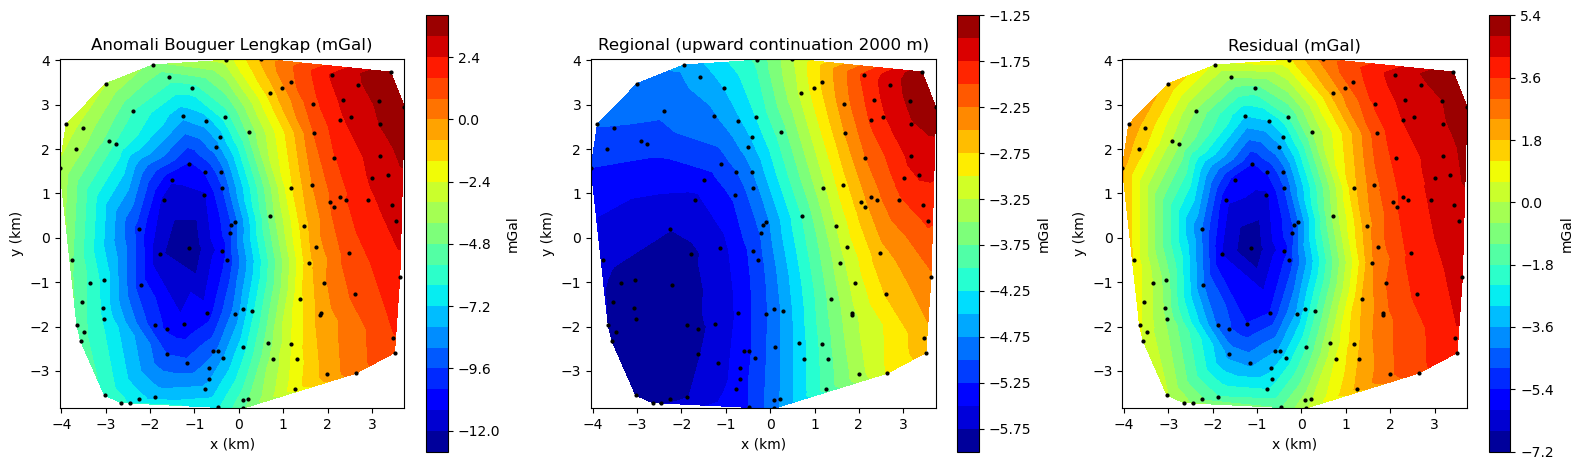

In [9]:
import os
import json
import math
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

np.random.seed(7)

# PARAMETER (isian placeholder {{...}} pada prompt)
lokasi = "Cekungan Contoh (isi sesuai lokasi)"      # {{lokasi}}
densitas_reduksi = 2.67        # {{2.67 g/cm3}} densitas reduksi (dicatat di run_config.json)
h_uc_m = 2000.0                # {{h}} ketinggian upward continuation (m)
sel_grid_km = 0.25             # ukuran sel grid untuk upward continuation (km)
koef_fa = 0.3086               # mGal per m  (free-air)
koef_bg = 0.04193              # mGal per (g/cm3 . m)  (Bouguer plat tak hingga)
toleransi_mgal = 0.01          # {{0.01 mGal}} toleransi hitung ulang independen
batas_korelasi = 0.5           # |r| residual vs elevasi di atas nilai ini = korelasi kuat

path_grav = "data/raw/gravity_cekungan.csv"
path_base = "data/raw/base_station.csv"
folder_out = "results/gravity"
os.makedirs("data/raw", exist_ok=True)
os.makedirs(folder_out, exist_ok=True)


# PEMBANGKIT DATA CONTOH (dilewati bila file data lapangan sudah ada)
if (not os.path.exists(path_grav)) or (not os.path.exists(path_base)):
    n_c = 120
    lon0_c, lat0_c = 119.45, -5.15
    x_c = np.random.uniform(-4, 4, n_c)
    y_c = np.random.uniform(-4, 4, n_c)
    lon_c = lon0_c + x_c / (111.32 * np.cos(np.radians(lat0_c)))
    lat_c = lat0_c + y_c / 110.57
    elev_c = np.random.uniform(5, 120, n_c)
    jam_c = np.sort(np.random.uniform(0.2, 7.8, n_c))
    tc_c = np.random.uniform(0.1, 1.2, n_c)
    t0_c = pd.Timestamp("2026-06-10 00:00:00")
    # CBA sintetis: cekungan memanjang utara-selatan + tren regional linear
    cba_c = -12 * np.exp(-0.5 * (((x_c + 1.0) / 1.4) ** 2 + (y_c / 3.0) ** 2)) + 0.7 * x_c + 0.4 * y_c
    phi_c = np.radians(lat_c)
    gn_c = 978032.67715 * (1 + 0.0053024 * np.sin(phi_c) ** 2 - 0.0000059 * np.sin(2 * phi_c) ** 2)
    g_abs_c = cba_c + gn_c - koef_fa * elev_c + koef_bg * densitas_reduksi * elev_c - tc_c
    g_abs_base_c, g_read_base_c, drift_c = 978105.00, 3010.00, 0.02
    baca_c = g_abs_c - g_abs_base_c + g_read_base_c + drift_c * jam_c + np.random.normal(0, 0.03, n_c)
    elev_c[[10, 55, 90]] = np.nan                  # stasiun tanpa elevasi (uji flag)
    baca_c[77] = np.nan                            # stasiun tanpa pembacaan (uji flag)
    pd.DataFrame({"station_id": ["G%03d" % (i + 1) for i in range(n_c)], "lat": lat_c.round(6), "lon": lon_c.round(6),
                  "elev_m": np.round(elev_c, 1), "g_obs_mgal": np.round(baca_c, 3),
                  "time_utc": (t0_c + pd.to_timedelta(jam_c, unit="h")).strftime("%Y-%m-%d %H:%M:%S"),
                  "terrain_corr_mgal": tc_c.round(3)}).to_csv(path_grav, index=False)
    pd.DataFrame({"g_abs_base_mgal": [g_abs_base_c], "g_read_base_mgal": [g_read_base_c],
                  "time_base_utc": [str(t0_c)], "drift_mgal_per_jam": [drift_c]}).to_csv(path_base, index=False)

with open(path_grav, "rb") as f1:
    sha_awal = hashlib.sha256(f1.read()).hexdigest()
with open(path_base, "rb") as f2:
    sha_base_awal = hashlib.sha256(f2.read()).hexdigest()
raw = pd.read_csv(path_grav)
base = pd.read_csv(path_base)


# PEMERIKSAAN KECUKUPAN DATA (hentikan jika tidak memadai)
for k in ["station_id", "lat", "lon", "elev_m", "g_obs_mgal", "time_utc"]:
    if k not in raw.columns:
        raise SystemExit("Kolom '%s' tidak ada pada gravity_cekungan.csv. Data tidak memadai." % k)
for k in ["g_abs_base_mgal", "g_read_base_mgal", "time_base_utc", "drift_mgal_per_jam"]:
    if k not in base.columns:
        raise SystemExit("Kolom '%s' tidak ada pada base_station.csv. Pengikatan base/drift tidak dapat dilakukan." % k)
n_input = len(raw)
if n_input < 30:
    raise SystemExit("Stasiun terlalu sedikit (< 30) untuk pemisahan regional-residual yang layak.")

ada_terrain = "terrain_corr_mgal" in raw.columns
raw["t"] = pd.to_datetime(raw["time_utc"], errors="coerce")
g_abs_base = float(base["g_abs_base_mgal"].iloc[0])
g_read_base = float(base["g_read_base_mgal"].iloc[0])
t_base = pd.to_datetime(base["time_base_utc"].iloc[0])
drift = float(base["drift_mgal_per_jam"].iloc[0])

print("Lokasi: %s | jumlah stasiun input: %d" % (lokasi, n_input))
print("Base: g absolut %.3f mGal | pembacaan base %.3f | waktu %s | drift %.4f mGal/jam" % (g_abs_base, g_read_base, t_base, drift))
print("Densitas reduksi: %.2f g/cm3 | tinggi upward continuation: %.0f m" % (densitas_reduksi, h_uc_m))


# (1) STASIUN YANG TIDAK DAPAT DIPROSES -> flags.csv (tidak dikoreksi diam-diam)
flags = []
valid = np.ones(n_input, dtype=bool)
for i in range(n_input):
    alasan = []
    if pd.isna(raw["elev_m"].iloc[i]):
        alasan.append("elevasi kosong (free-air/Bouguer tidak dapat dihitung)")
    if pd.isna(raw["g_obs_mgal"].iloc[i]):
        alasan.append("g_obs kosong")
    if pd.isna(raw["lat"].iloc[i]) or pd.isna(raw["lon"].iloc[i]):
        alasan.append("koordinat kosong")
    if pd.isna(raw["t"].iloc[i]):
        alasan.append("waktu tidak valid (drift tidak dapat dikoreksi)")
    if len(alasan) > 0:
        flags.append({"station_id": raw["station_id"].iloc[i], "alasan": "; ".join(alasan)})
        valid[i] = False

df = raw[valid].reset_index(drop=True)
terrain = df["terrain_corr_mgal"].fillna(0.0).values if ada_terrain else np.zeros(len(df))


# (2) URUTAN KOREKSI (eksplisit): drift -> pasang surut -> lintang normal -> free-air -> Bouguer sederhana -> terrain
print("\n=== (2) URUTAN KOREKSI ===")
dt_jam = ((df["t"] - t_base).dt.total_seconds() / 3600.0).values
if (dt_jam < 0).any():
    print("PERINGATAN: %d stasiun diukur sebelum pembacaan base awal; drift diekstrapolasi (kurang andal)." % int((dt_jam < 0).sum()))
print("1. Drift     : g_corr = g_abs_base + [g_obs - drift*(t - t_base) - g_read_base]; drift = %.4f mGal/jam" % drift)
g_corr_drift = g_abs_base + (df["g_obs_mgal"].values - drift * dt_jam - g_read_base)
print("2. Pasut     : kolom koreksi pasang surut TIDAK ada pada input -> TIDAK diterapkan (catat sebagai keterbatasan).")
phi = np.radians(df["lat"].values)
g_normal = 978032.67715 * (1 + 0.0053024 * np.sin(phi) ** 2 - 0.0000059 * np.sin(2 * phi) ** 2)
print("3. Lintang   : g_n = 978032.67715 (1 + 0.0053024 sin^2(phi) - 0.0000059 sin^2(2 phi)) mGal")
free_air = koef_fa * df["elev_m"].values
print("4. Free-air  : FAC = %.4f x h (mGal; h dalam m), ditambahkan" % koef_fa)
bouguer_simple = koef_bg * densitas_reduksi * df["elev_m"].values
print("5. Bouguer   : BC = %.5f x rho x h (rho = %.2f g/cm3), dikurangkan" % (koef_bg, densitas_reduksi))
if ada_terrain:
    print("6. Terrain   : memakai kolom terrain_corr_mgal dari input (ditambahkan)")
else:
    print("6. Terrain   : kolom terrain_corr_mgal tidak ada -> TIDAK diterapkan; CBA = SBA (catat sebagai keterbatasan)")
cba = g_corr_drift - g_normal + free_air - bouguer_simple + terrain
print("   CBA = g_corr_drift - g_n + FAC - BC + TC   (semua mGal)")

# stasiun dengan hasil tidak finite dikeluarkan ke flags
ok_finite = np.isfinite(cba) & np.isfinite(g_corr_drift) & np.isfinite(g_normal)
if (~ok_finite).any():
    for i in np.where(~ok_finite)[0]:
        flags.append({"station_id": df["station_id"].iloc[i], "alasan": "hasil koreksi tidak finite"})
df = df[ok_finite].reset_index(drop=True)
g_corr_drift = g_corr_drift[ok_finite]
g_normal = g_normal[ok_finite]
free_air = free_air[ok_finite]
bouguer_simple = bouguer_simple[ok_finite]
terrain = terrain[ok_finite]
cba = cba[ok_finite]
n_proses = len(df)
print("Stasiun diproses: %d | stasiun di-flag: %d | total input: %d" % (n_proses, len(flags), n_input))


# (3) PEMISAHAN REGIONAL-RESIDUAL: upward continuation pada ketinggian h
x = ((df["lon"] - df["lon"].mean()) * 111.32 * np.cos(np.radians(df["lat"].mean()))).values       # km
y = ((df["lat"] - df["lat"].mean()) * 110.57).values                                               # km
xi = np.arange(x.min(), x.max() + sel_grid_km, sel_grid_km)
yi = np.arange(y.min(), y.max() + sel_grid_km, sel_grid_km)
XI, YI = np.meshgrid(xi, yi)
ny, nx = XI.shape
d2 = (XI.ravel()[:, None] - x[None, :]) ** 2 + (YI.ravel()[:, None] - y[None, :]) ** 2
w = 1.0 / (d2 + 1e-6)                                                      # IDW pangkat 2
zg = ((w * cba[None, :]).sum(axis=1) / w.sum(axis=1)).reshape(ny, nx)
zmean = zg.mean()
npad = max(nx, ny) // 2
zp = np.pad(zg - zmean, npad, mode="reflect")                              # padding untuk mengurangi efek tepi FFT
kx = 2 * np.pi * np.fft.fftfreq(zp.shape[1], d=sel_grid_km)               # rad/km
ky = 2 * np.pi * np.fft.fftfreq(zp.shape[0], d=sel_grid_km)
KX, KY = np.meshgrid(kx, ky)
Kr = np.sqrt(KX ** 2 + KY ** 2)
uc = np.real(np.fft.ifft2(np.fft.fft2(zp) * np.exp(-(h_uc_m / 1000.0) * Kr)))
uc = uc[npad:-npad, npad:-npad] + zmean

fx = (x - xi[0]) / sel_grid_km
fy = (y - yi[0]) / sel_grid_km
ix = np.clip(np.floor(fx).astype(int), 0, nx - 2)
iy = np.clip(np.floor(fy).astype(int), 0, ny - 2)
tx = fx - ix
ty = fy - iy
regional = (uc[iy, ix] * (1 - tx) * (1 - ty) + uc[iy, ix + 1] * tx * (1 - ty)
            + uc[iy + 1, ix] * (1 - tx) * ty + uc[iy + 1, ix + 1] * tx * ty)
residual = cba - regional
print("\n=== (3) PEMISAHAN REGIONAL-RESIDUAL ===")
print("Metode: grid IDW (%d x %d sel, %.2f km) -> upward continuation FFT exp(-h|k|), h = %.0f m -> regional di stasiun (bilinear)." % (
    nx, ny, sel_grid_km, h_uc_m))
print("Residual = CBA - regional. Tinggi h dan IDW memengaruhi hasil; ini asumsi pengolahan, bukan kebenaran tunggal.")


# OUTPUT
hasil = pd.DataFrame({"station_id": df["station_id"].values, "g_corr_drift": g_corr_drift.round(4),
                      "g_normal": g_normal.round(4), "free_air": free_air.round(4),
                      "bouguer_simple": bouguer_simple.round(4), "terrain": terrain.round(4),
                      "bouguer_complete": cba.round(4), "regional": regional.round(4), "residual": residual.round(4)})
hasil.to_csv(os.path.join(folder_out, "bouguer.csv"), index=False)
flags_df = pd.DataFrame(flags, columns=["station_id", "alasan"])
flags_df.to_csv(os.path.join(folder_out, "flags.csv"), index=False)

konfig = {"densitas_reduksi_g_cm3": densitas_reduksi, "tinggi_upward_continuation_m": h_uc_m,
          "rumus_lintang_normal": "g_n = 978032.67715 (1 + 0.0053024 sin^2(phi) - 0.0000059 sin^2(2 phi)) mGal (GRS80)",
          "koef_free_air_mgal_per_m": koef_fa, "koef_bouguer_mgal_per_gcm3_m": koef_bg,
          "urutan_koreksi": ["drift", "pasang surut (tidak diterapkan: tidak ada data)", "lintang normal", "free-air",
                             "Bouguer sederhana", "terrain" if ada_terrain else "terrain (tidak diterapkan: tidak ada data)"],
          "definisi_kolom_bouguer_csv": {"g_corr_drift": "g absolut setelah koreksi drift (mGal)", "g_normal": "gravitasi normal lintang (mGal)",
                                         "free_air": "koreksi free-air (mGal)", "bouguer_simple": "koreksi Bouguer sederhana (mGal)",
                                         "terrain": "koreksi terrain (mGal)", "bouguer_complete": "CBA = g_corr_drift - g_normal + free_air - bouguer_simple + terrain",
                                         "regional": "anomali regional (upward continuation, mGal)", "residual": "CBA - regional (mGal)"},
          "drift_mgal_per_jam": drift, "sel_grid_km": sel_grid_km,
          "versi_package": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                            "matplotlib": matplotlib.__version__}}
with open(os.path.join(folder_out, "run_config.json"), "w") as f_cfg:
    json.dump(konfig, f_cfg, indent=2)

kolom_stat = ["g_corr_drift", "g_normal", "free_air", "bouguer_simple", "terrain", "bouguer_complete", "regional", "residual"]
stat = hasil[kolom_stat].describe().loc[["count", "min", "max", "mean", "std"]].round(3)
md = ["# Ringkasan Pengolahan Gravitasi", "",
      "- Lokasi: %s" % lokasi,
      "- Jumlah stasiun input: %d | diproses: %d | di-flag: %d" % (n_input, n_proses, len(flags)),
      "- Densitas reduksi %.2f g/cm3; upward continuation h = %.0f m" % (densitas_reduksi, h_uc_m),
      "- Urutan koreksi: drift -> pasut (tidak diterapkan) -> lintang normal -> free-air -> Bouguer sederhana -> terrain",
      "- Semua kolom dalam mGal.", "", "## Statistik tiap kolom", "```", stat.to_string(), "```", "", "## Stasiun di-flag"]
if len(flags) == 0:
    md.append("- tidak ada")
for r in range(len(flags_df)):
    md.append("- %s: %s" % (flags_df["station_id"].iloc[r], flags_df["alasan"].iloc[r]))
md += ["", "## Batasan",
       "- Tidak ada klaim hidrokarbon atau mineral tertentu; hasil hanya untuk memilih area prioritas survei seismik lanjutan.",
       "- Pasang surut dan (bila kolom tidak ada) terrain tidak dikoreksi."]
with open(os.path.join(folder_out, "summary.md"), "w", encoding="utf-8") as f_md:
    f_md.write("\n".join(md))

print("\n=== STATISTIK KOLOM (mGal) ===")
print(stat.to_string())
print("\n=== flags.csv ===")
print(flags_df.to_string(index=False))
print("\nFile keluaran:", sorted(os.listdir(folder_out)))


# KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Semua nilai anomali finite: %s" % ("OK" if np.isfinite(hasil[["bouguer_complete", "regional", "residual"]].values).all() else "ADA NILAI TIDAK FINITE"))
print("Stasiun output + flag = %d + %d = %d (input %d) -> %s" % (n_proses, len(flags), n_proses + len(flags), n_input,
                                                              "OK" if n_proses + len(flags) == n_input else "TIDAK SAMA"))
print("Satuan tiap kolom eksplisit (mGal) dan rumus/konstanta di run_config.json: OK")


# VERIFIKASI (opsional)
print("\n=== VERIFIKASI ===")
raw2 = pd.read_csv(path_grav)
pilih = np.random.choice(n_proses, size=min(5, n_proses), replace=False)
gagal = 0
for i in sorted(pilih):
    sid = hasil["station_id"].iloc[i]
    baris = raw2[raw2["station_id"] == sid].iloc[0]
    jam = (pd.to_datetime(baris["time_utc"]) - t_base).total_seconds() / 3600.0
    g_c = g_abs_base + (float(baris["g_obs_mgal"]) - drift * jam - g_read_base)
    ph = math.radians(float(baris["lat"]))
    g_n = 978032.67715 * (1 + 0.0053024 * math.sin(ph) ** 2 - 0.0000059 * math.sin(2 * ph) ** 2)
    cba_c = g_c - g_n + koef_fa * float(baris["elev_m"]) - koef_bg * densitas_reduksi * float(baris["elev_m"]) + float(baris["terrain_corr_mgal"] if ada_terrain else 0.0)
    beda = abs(cba_c - hasil["bouguer_complete"].iloc[i])
    status = "OK" if beda < toleransi_mgal else "BERBEDA"
    if beda >= toleransi_mgal:
        gagal = gagal + 1
    print("%s: CBA hitung ulang = %.4f vs utama = %.4f mGal, selisih %.5f mGal -> %s" % (sid, cba_c, hasil["bouguer_complete"].iloc[i], beda, status))
if gagal > 0:
    print("-> Ada %d stasiun berbeda; laporkan rumus yang berbeda." % gagal)
r_elev = np.corrcoef(hasil["residual"].values, df["elev_m"].values)[0, 1]
print("Korelasi residual vs elevasi: r = %.3f -> %s" % (r_elev, "tidak ada korelasi kuat" if abs(r_elev) < batas_korelasi else
                                                       "KORELASI KUAT: kemungkinan koreksi terrain kurang memadai (dilaporkan, tidak diperbaiki sendiri)"))

with open(path_grav, "rb") as f3:
    sha_akhir = hashlib.sha256(f3.read()).hexdigest()
with open(path_base, "rb") as f4:
    sha_base_akhir = hashlib.sha256(f4.read()).hexdigest()
if sha_awal != sha_akhir or sha_base_awal != sha_base_akhir:
    raise SystemExit("File input BERUBAH selama prosedur. Hentikan dan laporkan.")
print("SHA-256 file input identik sebelum dan sesudah prosedur.")


# VISUAL (tambahan, di luar kontrak output)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, nilai, judul in [(ax[0], cba, "Anomali Bouguer Lengkap (mGal)"), (ax[1], regional, "Regional (upward continuation %.0f m)" % h_uc_m),
                        (ax[2], residual, "Residual (mGal)")]:
    c = a.tricontourf(x, y, nilai, 20, cmap="jet")
    plt.colorbar(c, ax=a, label="mGal")
    a.scatter(x, y, c="k", s=4)
    a.set_title(judul)
    a.set_xlabel("x (km)")
    a.set_ylabel("y (km)")
    a.set_aspect("equal")
plt.tight_layout()
plt.savefig(os.path.join(folder_out, "peta_anomali_gravitasi.png"), dpi=130)
plt.show()


---

## Prompt 5 — QC dan Pra-pengolahan Data Magnetik untuk Deteksi Struktur Terpendam

### [R] Role
Bertindaklah sebagai reviewer QC data magnetik yang bertugas menyiapkan data bersih sebelum diserahkan ke interpreter manusia, bukan menjadi interpreter itu sendiri. Fokus kerja: (1) memverifikasi bahwa koreksi variasi harian memakai data base station yang benar-benar menaungi seluruh waktu survei, bukan diekstrapolasi diam-diam, (2) memastikan pengurangan medan referensi IGRF memakai model dan epoch yang dinyatakan pengguna, tanpa mengunduh atau mengganti model sendiri, (3) mendeteksi spike dan gap pada grid dengan ambang yang eksplisit dan dapat diaudit, bukan penilaian subjektif, dan (4) secara sadar tidak melangkah ke reduksi ke kutub (RTP) atau estimasi kedalaman sumber, karena RTP di lintang rendah rawan artefak dan keputusan itu perlu pertimbangan manusia dengan konteks geologi tambahan.

### [T] Task
Periksa dan kurangkan variasi harian serta medan referensi IGRF dari data magnetik total `data/raw/mag_terpendam.csv`, lalu buat grid anomali residual dan tandai spike serta gap. Jangan menjalankan reduksi ke kutub atau menentukan jenis mineral/objek terpendam.

### [C] Context
Survei magnetik di lahan `{{lokasi}}` yang diduga mengandung mineral bijih besi atau struktur logam terpendam. Hasil grid menjadi input tahap interpretasi yang dilakukan manusia untuk menentukan titik bor verifikasi; tahap ini hanya menyiapkan data bersih.

### [I] Input
- `data/raw/mag_terpendam.csv`: `point_id`, `lat`, `lon` (WGS84), `time_utc`, `B_nT`, ketinggian sensor `{{m}}`.
- `data/raw/base_mag.csv`: `time_utc`, `B_base_nT`.
- IGRF: `{{model dan epoch, mis. IGRF-13 2020}}` dari `{{file/nilai yang diberikan}}`.
- Grid: sel `{{m}}`, metode `{{minimum curvature}}`.

### [K] Constraints
- Jangan mengubah `data/raw/`.
- Jangan menjalankan RTP/RTE atau estimasi kedalaman sumber; catat bahwa RTP di lintang rendah butuh keputusan manusia.
- Jangan menghapus spike; hanya beri flag dengan ambang `{{nT}}` yang dinyatakan.
- Jangan mengunduh model IGRF; gunakan nilai yang diberikan.
- Jika interval waktu base station tidak mencakup survei, hentikan dan laporkan.

### [O] Output (rencana teks)
- `results/mag/anomaly.csv`: `point_id`, `B_corr_nT`, `IGRF_nT`, `anomaly_nT`, `flag`.
- `results/mag/grid_residual.csv` (atau `.tif`): grid anomali dengan CRS dan ukuran sel tercatat.
- `results/mag/qc_report.md`: jumlah titik, spike, gap, cakupan waktu base.
- `results/mag/run_config.json`: ambang spike, model IGRF, metode grid.

### [Q] Quality criteria
- Jumlah titik input sama dengan output (termasuk yang di-flag).
- Nilai anomali finite; satuan nT.
- Semua parameter yang memengaruhi hasil tercatat.
- Tidak ada interpretasi jenis mineral atau objek pada laporan QC ini.

### [V] Optional verification
- Check: bandingkan statistik anomali sebelum dan sesudah koreksi harian. Expected: rentang lebih kecil setelah koreksi. Jika tidak: laporkan dan periksa sinkronisasi waktu.
- Check: cek titik di tepi grid. Expected: tidak ada ekstrapolasi jauh dari data. Jika ada: beri flag pada sel tersebut.

```
Input  : data/raw/mag_terpendam.csv + data/raw/base_mag.csv + nilai IGRF yang diberikan
Model  : koreksi variasi harian -> kurangi IGRF -> flag spike & gap -> grid minimum curvature (TANPA RTP/RTE, TANPA estimasi kedalaman)
Output : results/mag/ anomaly.csv, grid_residual.csv, qc_report.md, run_config.json
Cek    : statistik sebelum/sesudah koreksi harian + flag sel tepi grid
```

Lokasi: Lahan Prospek Contoh (isi sesuai lokasi) | titik input: 2224 | titik valid: 2224
Waktu survei : 2026-05-20 00:12:00 s.d. 2026-05-20 05:36:00
Waktu base   : 2026-05-20 00:00:00 s.d. 2026-05-20 06:00:00 (73 pembacaan)
Cakupan base station menaungi seluruh waktu survei: OK

=== (1) KOREKSI VARIASI HARIAN ===
B_corr = B_obs - (B_base(t) - B_base_ref); B_base diinterpolasi ke waktu tiap titik; B_base_ref = rata-rata base = 44515.45 nT
Rentang variasi harian pada base: 12.3 nT (puncak ke puncak)

=== (2) PENGURANGAN IGRF ===
Model: IGRF-14, epoch 2025.0 (isi sesuai model & epoch yang diberikan) | nilai referensi 44500.0 nT (gradien lat 0.00, lon 0.00 nT/derajat)
anomali = B_corr - IGRF. Rata-rata anomali 15.7 nT: offset level base terhadap IGRF TIDAK dihilangkan (keputusan interpreter).

=== (3) SPIKE ===
Kriteria: |anomali - median 8 tetangga terdekat| > 50 nT (spike hanya diberi flag, TIDAK dihapus).
Jumlah spike: 3
  M0301: anomali 105.7 nT, simpangan terhadap median tetangga +90.

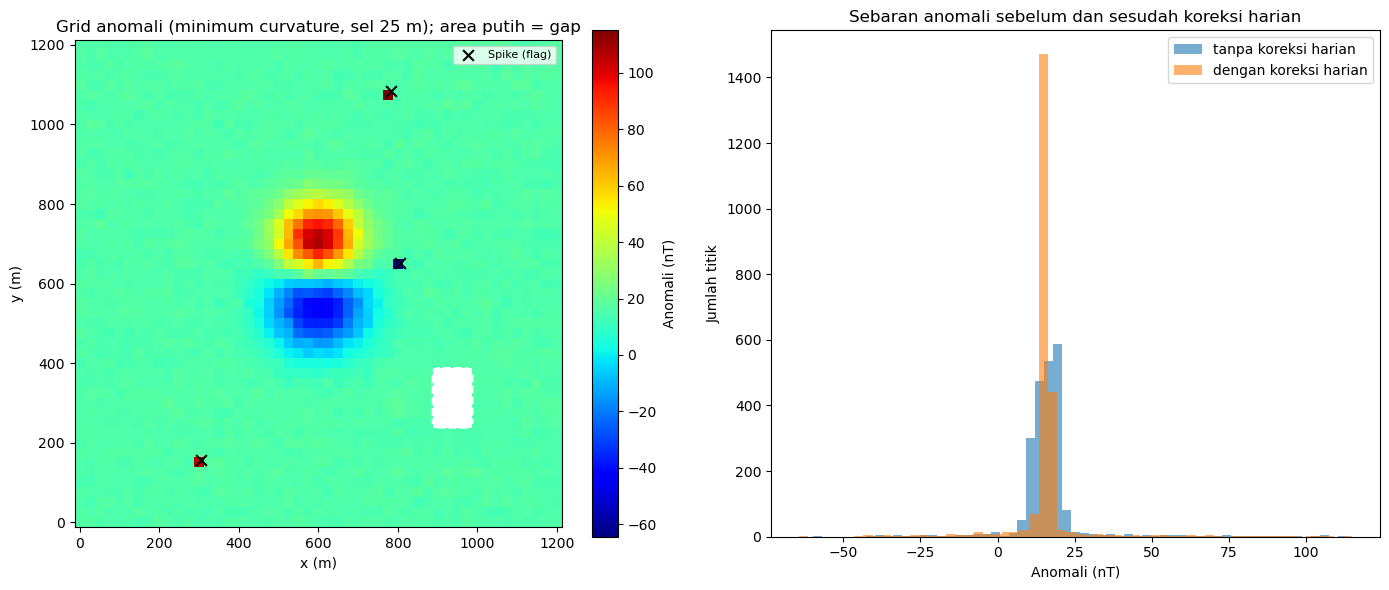

In [10]:
import os
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

np.random.seed(11)

# PARAMETER (isian placeholder {{...}} pada prompt)
lokasi = "Lahan Prospek Contoh (isi sesuai lokasi)"      # {{lokasi}}
tinggi_sensor_m = 1.5                                     # {{m}} ketinggian sensor
igrf_model = "IGRF-14, epoch 2025.0 (isi sesuai model & epoch yang diberikan)"   # {{model dan epoch}}
igrf_ref_nT = 44500.0                                     # {{file/nilai yang diberikan}} IGRF di titik referensi (nT)
igrf_grad_lat_nT_per_deg = 0.0                            # gradien IGRF terhadap lintang (bila diberikan)
igrf_grad_lon_nT_per_deg = 0.0                            # gradien IGRF terhadap bujur (bila diberikan)
ambang_spike_nT = 50.0         # {{nT}} |anomali - median k tetangga| di atas nilai ini = spike
k_tetangga = 8                 # jumlah tetangga terdekat untuk uji spike
sel_grid_m = 25.0              # {{m}} ukuran sel grid
metode_grid = "minimum curvature"                         # {{minimum curvature}}
n_iter_grid = 3000             # iterasi maksimum relaksasi minimum curvature
omega = 0.5                    # faktor redaman iterasi (stabil untuk operator biharmonik)
ambang_gap_m = 60.0            # sel dengan jarak ke data terdekat > nilai ini = gap/ekstrapolasi

path_mag = "data/raw/mag_terpendam.csv"
path_base = "data/raw/base_mag.csv"
folder_out = "results/mag"
os.makedirs("data/raw", exist_ok=True)
os.makedirs(folder_out, exist_ok=True)


# PEMBANGKIT DATA CONTOH (dilewati bila file data lapangan sudah ada)
if (not os.path.exists(path_mag)) or (not os.path.exists(path_base)):
    nxc, nyc = 48, 48
    lat0_c, lon0_c = -4.50, 119.90
    urutan = []
    for j in range(nyc):
        rentang_i = range(nxc) if j % 2 == 0 else range(nxc - 1, -1, -1)       # jalur survei bolak-balik
        for i in rentang_i:
            if not ((34 <= i <= 41) and (8 <= j <= 17)):                        # blok tanpa data (gap buatan)
                urutan.append((i, j))
    n_c = len(urutan)
    xc = np.array([u[0] for u in urutan]) * 25.0 + np.random.uniform(-5, 5, n_c)
    yc = np.array([u[1] for u in urutan]) * 25.0 + np.random.uniform(-5, 5, n_c)
    jam_c = np.linspace(0.2, 5.6, n_c)
    dv_c = 12 * np.sin(np.pi * jam_c / 6.0)                                      # variasi harian buatan
    anom_c = (110 * np.exp(-((xc - 600) ** 2 + (yc - 700) ** 2) / (2 * 70 ** 2))
              - 70 * np.exp(-((xc - 600) ** 2 + (yc - 560) ** 2) / (2 * 85 ** 2)))
    b_c = igrf_ref_nT + 8.0 + anom_c + dv_c + np.random.normal(0, 1.0, n_c)
    b_c[[300, 1200, 2000]] = b_c[[300, 1200, 2000]] + np.array([90.0, -80.0, 100.0])    # spike buatan
    t0_c = pd.Timestamp("2026-05-20 00:00:00")
    pd.DataFrame({"point_id": ["M%04d" % (i + 1) for i in range(n_c)],
                  "lat": (lat0_c + yc / 110574.0).round(7),
                  "lon": (lon0_c + xc / (111320.0 * np.cos(np.radians(lat0_c)))).round(7),
                  "time_utc": (t0_c + pd.to_timedelta(jam_c, unit="h")).strftime("%Y-%m-%d %H:%M:%S"),
                  "B_nT": b_c.round(2)}).to_csv(path_mag, index=False)
    tb_c = np.arange(0, 6.01, 1 / 12)
    pd.DataFrame({"time_utc": (t0_c + pd.to_timedelta(tb_c, unit="h")).strftime("%Y-%m-%d %H:%M:%S"),
                  "B_base_nT": (igrf_ref_nT + 8.0 + 12 * np.sin(np.pi * tb_c / 6.0) + np.random.normal(0, 0.3, len(tb_c))).round(2)}).to_csv(path_base, index=False)

with open(path_mag, "rb") as f1:
    sha_awal = hashlib.sha256(f1.read()).hexdigest()
with open(path_base, "rb") as f2:
    sha_base_awal = hashlib.sha256(f2.read()).hexdigest()
mag = pd.read_csv(path_mag)
base = pd.read_csv(path_base)


# PEMERIKSAAN KECUKUPAN DATA (hentikan jika tidak memadai)
for k in ["point_id", "lat", "lon", "time_utc", "B_nT"]:
    if k not in mag.columns:
        raise SystemExit("Kolom '%s' tidak ada pada mag_terpendam.csv. Data tidak memadai." % k)
for k in ["time_utc", "B_base_nT"]:
    if k not in base.columns:
        raise SystemExit("Kolom '%s' tidak ada pada base_mag.csv. Koreksi variasi harian tidak dapat dilakukan." % k)
n_input = len(mag)
mag["t"] = pd.to_datetime(mag["time_utc"], errors="coerce")
base["t"] = pd.to_datetime(base["time_utc"], errors="coerce")
base = base.dropna(subset=["t", "B_base_nT"]).sort_values("t").reset_index(drop=True)
if len(base) < 5:
    raise SystemExit("Data base station terlalu sedikit (< 5 pembacaan).")

valid = (mag["t"].notna() & mag["lat"].notna() & mag["lon"].notna() & mag["B_nT"].notna()).values
if valid.sum() < 100:
    raise SystemExit("Titik valid terlalu sedikit (< 100) untuk grid.")

# cakupan waktu base station (hentikan bila tidak menaungi seluruh survei)
t_survei_min = mag["t"][valid].min()
t_survei_maks = mag["t"][valid].max()
cakupan_ok = (base["t"].min() <= t_survei_min) and (base["t"].max() >= t_survei_maks)
print("Lokasi: %s | titik input: %d | titik valid: %d" % (lokasi, n_input, int(valid.sum())))
print("Waktu survei : %s s.d. %s" % (t_survei_min, t_survei_maks))
print("Waktu base   : %s s.d. %s (%d pembacaan)" % (base["t"].min(), base["t"].max(), len(base)))
if not cakupan_ok:
    raise SystemExit("HENTI: interval waktu base station TIDAK mencakup seluruh waktu survei. Koreksi harian tidak diekstrapolasi; laporkan dan lengkapi data base.")
print("Cakupan base station menaungi seluruh waktu survei: OK")


# (1) KOREKSI VARIASI HARIAN:  B_corr = B_obs - (B_base(t) - B_base_ref)
t_ref = base["t"].iloc[0]
base_sec = (base["t"] - t_ref).dt.total_seconds().values
mag_sec = (mag["t"] - t_ref).dt.total_seconds().values
b_base_ref = float(base["B_base_nT"].mean())
B_corr = np.full(n_input, np.nan)
base_interp = np.interp(mag_sec[valid], base_sec, base["B_base_nT"].values)
B_corr[valid] = mag["B_nT"].values[valid] - (base_interp - b_base_ref)
print("\n=== (1) KOREKSI VARIASI HARIAN ===")
print("B_corr = B_obs - (B_base(t) - B_base_ref); B_base diinterpolasi ke waktu tiap titik; B_base_ref = rata-rata base = %.2f nT" % b_base_ref)
print("Rentang variasi harian pada base: %.1f nT (puncak ke puncak)" % (base["B_base_nT"].max() - base["B_base_nT"].min()))


# (2) PENGURANGAN IGRF (nilai yang diberikan, tidak diunduh)
lat_ref = float(mag["lat"][valid].mean())
lon_ref = float(mag["lon"][valid].mean())
IGRF = igrf_ref_nT + igrf_grad_lat_nT_per_deg * (mag["lat"].values - lat_ref) + igrf_grad_lon_nT_per_deg * (mag["lon"].values - lon_ref)
anomali = B_corr - IGRF
print("\n=== (2) PENGURANGAN IGRF ===")
print("Model: %s | nilai referensi %.1f nT (gradien lat %.2f, lon %.2f nT/derajat)" % (
    igrf_model, igrf_ref_nT, igrf_grad_lat_nT_per_deg, igrf_grad_lon_nT_per_deg))
print("anomali = B_corr - IGRF. Rata-rata anomali %.1f nT: offset level base terhadap IGRF TIDAK dihilangkan (keputusan interpreter)." % np.nanmean(anomali))


# koordinat lokal (m) dari WGS84 (aproksimasi equirectangular), titik asal = lat/lon minimum
lat0 = float(mag["lat"][valid].min())
lon0 = float(mag["lon"][valid].min())
xm = (mag["lon"].values - lon0) * 111320.0 * np.cos(np.radians(lat0))
ym = (mag["lat"].values - lat0) * 110574.0
xv = xm[valid]
yv = ym[valid]
av = anomali[valid]


# (3) DETEKSI SPIKE: |anomali - median k tetangga terdekat| > ambang (hanya diberi flag, tidak dihapus)
D2 = (xv[:, None] - xv[None, :]) ** 2 + (yv[:, None] - yv[None, :]) ** 2
np.fill_diagonal(D2, np.inf)
idx_k = np.argpartition(D2, k_tetangga, axis=1)[:, :k_tetangga]
dev = av - np.median(av[idx_k], axis=1)
spike_v = np.abs(dev) > ambang_spike_nT
flag = np.array(["data_tidak_valid"] * n_input, dtype=object)
flag_valid = np.where(spike_v, "spike", "ok")
flag[valid] = flag_valid
n_spike = int(spike_v.sum())
print("\n=== (3) SPIKE ===")
print("Kriteria: |anomali - median %d tetangga terdekat| > %.0f nT (spike hanya diberi flag, TIDAK dihapus)." % (k_tetangga, ambang_spike_nT))
print("Jumlah spike: %d" % n_spike)
idx_valid = np.where(valid)[0]
for s in np.where(spike_v)[0]:
    print("  %s: anomali %.1f nT, simpangan terhadap median tetangga %+.1f nT, x = %.0f m, y = %.0f m" % (
        mag["point_id"].iloc[idx_valid[s]], av[s], dev[s], xv[s], yv[s]))


# (4) GRID ANOMALI (minimum curvature, relaksasi iteratif dengan redaman)
xg = np.arange(xv.min(), xv.max() + sel_grid_m, sel_grid_m)
yg = np.arange(yv.min(), yv.max() + sel_grid_m, sel_grid_m)
XG, YG = np.meshgrid(xg, yg)
ny, nx = XG.shape
d2g = (XG.ravel()[:, None] - xv[None, :]) ** 2 + (YG.ravel()[:, None] - yv[None, :]) ** 2
jarak_min = np.sqrt(d2g.min(axis=1)).reshape(ny, nx)
terdekat = d2g.argmin(axis=1).reshape(ny, nx)

ix = np.clip(np.round((xv - xg[0]) / sel_grid_m).astype(int), 0, nx - 1)
iy = np.clip(np.round((yv - yg[0]) / sel_grid_m).astype(int), 0, ny - 1)
jumlah = np.zeros((ny, nx))
isi = np.zeros((ny, nx))
np.add.at(jumlah, (iy, ix), 1)
np.add.at(isi, (iy, ix), av)
sel_data = jumlah > 0
z0 = np.where(sel_data, isi / np.maximum(jumlah, 1), av[terdekat])        # tebakan awal: nilai data / titik terdekat
z = z0.copy()
for it in range(n_iter_grid):
    p = np.pad(z, 2, mode="edge")
    n4 = p[1:-3, 2:-2] + p[3:-1, 2:-2] + p[2:-2, 1:-3] + p[2:-2, 3:-1]
    dg = p[1:-3, 1:-3] + p[1:-3, 3:-1] + p[3:-1, 1:-3] + p[3:-1, 3:-1]
    n2 = p[0:-4, 2:-2] + p[4:, 2:-2] + p[2:-2, 0:-4] + p[2:-2, 4:]
    z_baru = (8 * n4 - 2 * dg - n2) / 20.0                               # biharmonik: 20 z = 8 S(n4) - 2 S(diag) - S(n2)
    z_upd = z + omega * (z_baru - z)
    z_upd[sel_data] = z0[sel_data]                                       # node berdata tetap
    selisih_maks = np.abs(z_upd - z).max()
    z = z_upd
    if selisih_maks < 1e-4:
        break
grid_anom = z
print("\n=== (4) GRID ===")
print("Metode: %s | sel %.0f m | %d x %d sel | iterasi %d (perubahan maks terakhir %.2e nT)" % (
    metode_grid, sel_grid_m, nx, ny, it + 1, selisih_maks))

# flag sel grid: gap/ekstrapolasi (jauh dari data) dan sel yang memuat spike
grid_flag = np.full((ny, nx), "ok", dtype=object)
sel_spike = np.zeros((ny, nx), dtype=bool)
sel_spike[iy[spike_v], ix[spike_v]] = True
grid_flag[sel_spike] = "mengandung_spike"
gap = jarak_min > ambang_gap_m
grid_flag[gap] = "gap_ekstrapolasi"
n_gap = int(gap.sum())
tepi = np.zeros((ny, nx), dtype=bool)
tepi[0, :] = True
tepi[-1, :] = True
tepi[:, 0] = True
tepi[:, -1] = True
n_gap_tepi = int((gap & tepi).sum())
print("Sel gap/ekstrapolasi (jarak ke data terdekat > %.0f m): %d dari %d sel | di tepi grid: %d" % (ambang_gap_m, n_gap, nx * ny, n_gap_tepi))
print("Sel yang memuat spike: %d" % int(sel_spike.sum()))


# OUTPUT
crs_teks = "CRS lokal (m): x timur, y utara; turunan WGS84 (aproksimasi equirectangular) dengan titik asal lat0=%.6f, lon0=%.6f" % (lat0, lon0)
tabel_anom = pd.DataFrame({"point_id": mag["point_id"].values, "B_corr_nT": np.round(B_corr, 3),
                           "IGRF_nT": np.round(IGRF, 3), "anomaly_nT": np.round(anomali, 3), "flag": flag})
tabel_anom.to_csv(os.path.join(folder_out, "anomaly.csv"), index=False)

lon_g = lon0 + XG / (111320.0 * np.cos(np.radians(lat0)))
lat_g = lat0 + YG / 110574.0
tabel_grid = pd.DataFrame({"x_m": XG.ravel(), "y_m": YG.ravel(), "lon": lon_g.ravel().round(7), "lat": lat_g.ravel().round(7),
                           "anomaly_nT": grid_anom.ravel().round(3), "jarak_data_terdekat_m": jarak_min.ravel().round(1),
                           "flag_grid": grid_flag.ravel()})
with open(os.path.join(folder_out, "grid_residual.csv"), "w", encoding="utf-8") as f_g:
    f_g.write("# CRS: %s\n" % crs_teks)
    f_g.write("# cell_size_m: %.1f\n" % sel_grid_m)
    f_g.write("# metode_grid: %s\n" % metode_grid)
    f_g.write("# satuan anomaly_nT: nT (anomali setelah koreksi harian dan IGRF; BUKAN RTP)\n")
tabel_grid.to_csv(os.path.join(folder_out, "grid_residual.csv"), mode="a", index=False)

konfig = {"ambang_spike_nT": ambang_spike_nT, "k_tetangga": k_tetangga, "model_igrf": igrf_model,
          "igrf_ref_nT": igrf_ref_nT, "igrf_grad_lat_nT_per_deg": igrf_grad_lat_nT_per_deg, "igrf_grad_lon_nT_per_deg": igrf_grad_lon_nT_per_deg,
          "metode_grid": metode_grid, "sel_grid_m": sel_grid_m, "n_iterasi_grid": int(it + 1), "omega": omega,
          "ambang_gap_m": ambang_gap_m, "tinggi_sensor_m": tinggi_sensor_m, "B_base_ref_nT": b_base_ref,
          "crs_grid": crs_teks, "RTP_RTE_estimasi_kedalaman": "TIDAK dijalankan (butuh keputusan manusia, terutama di lintang rendah)",
          "versi_package": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                            "matplotlib": matplotlib.__version__}}
with open(os.path.join(folder_out, "run_config.json"), "w") as f_cfg:
    json.dump(konfig, f_cfg, indent=2)

md = ["# Laporan QC dan Pra-pengolahan Data Magnetik", "",
      "- Lokasi: %s | ketinggian sensor %.1f m" % (lokasi, tinggi_sensor_m),
      "- Jumlah titik: %d (valid: %d, tidak valid: %d)" % (n_input, int(valid.sum()), int((~valid).sum())),
      "- Spike (ambang %.0f nT terhadap median %d tetangga): %d titik (diberi flag, tidak dihapus)" % (ambang_spike_nT, k_tetangga, n_spike),
      "- Gap/ekstrapolasi pada grid (jarak ke data > %.0f m): %d sel dari %d (di tepi grid: %d)" % (ambang_gap_m, n_gap, nx * ny, n_gap_tepi),
      "- Cakupan waktu base: %s s.d. %s menaungi survei %s s.d. %s" % (base["t"].min(), base["t"].max(), t_survei_min, t_survei_maks),
      "- Koreksi harian memakai B_base_ref = %.2f nT; IGRF: %s, nilai referensi %.1f nT" % (b_base_ref, igrf_model, igrf_ref_nT),
      "- Anomali: %.1f s.d. %.1f nT (rata-rata %.1f nT)" % (np.nanmin(anomali), np.nanmax(anomali), np.nanmean(anomali)),
      "- Grid: %s, sel %.0f m, %d x %d" % (metode_grid, sel_grid_m, nx, ny), "",
      "## Catatan",
      "- RTP/RTE dan estimasi kedalaman sumber TIDAK dijalankan; RTP di lintang rendah rawan artefak dan butuh keputusan manusia.",
      "- Tidak ada interpretasi jenis mineral atau objek pada laporan QC ini."]
with open(os.path.join(folder_out, "qc_report.md"), "w", encoding="utf-8") as f_md:
    f_md.write("\n".join(md))

print("\n=== OUTPUT ===")
print(tabel_anom.head(6).to_string(index=False))
print("File keluaran:", sorted(os.listdir(folder_out)))


# KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Jumlah titik input = output (termasuk yang di-flag): %d = %d -> %s" % (n_input, len(tabel_anom), "OK" if n_input == len(tabel_anom) else "TIDAK SAMA"))
print("Nilai anomali finite untuk titik valid (satuan nT): %s" % ("OK" if np.isfinite(anomali[valid]).all() else "ADA NILAI TIDAK FINITE"))
print("Parameter yang memengaruhi hasil tercatat di run_config.json: OK")
print("Interpretasi jenis mineral atau objek pada laporan: tidak ada")


# VERIFIKASI (opsional)
print("\n=== VERIFIKASI ===")
anom_tanpa = mag["B_nT"].values[valid] - IGRF[valid]
anom_dengan = anomali[valid]
ok_pts = ~spike_v                      # spike (flag) dikeluarkan dari perbandingan agar ekstrem tidak menutupi efek koreksi harian
print("Semua titik:")
print("  TANPA koreksi harian : rentang %.1f nT (%.1f s.d. %.1f), std %.2f nT" % (
    anom_tanpa.max() - anom_tanpa.min(), anom_tanpa.min(), anom_tanpa.max(), anom_tanpa.std()))
print("  DENGAN koreksi harian: rentang %.1f nT (%.1f s.d. %.1f), std %.2f nT" % (
    anom_dengan.max() - anom_dengan.min(), anom_dengan.min(), anom_dengan.max(), anom_dengan.std()))
r_tanpa = anom_tanpa[ok_pts].max() - anom_tanpa[ok_pts].min()
r_dengan = anom_dengan[ok_pts].max() - anom_dengan[ok_pts].min()
print("Titik non-spike (%d titik):" % int(ok_pts.sum()))
print("  TANPA koreksi harian : rentang %.1f nT, std %.2f nT" % (r_tanpa, anom_tanpa[ok_pts].std()))
print("  DENGAN koreksi harian: rentang %.1f nT, std %.2f nT" % (r_dengan, anom_dengan[ok_pts].std()))
if r_dengan < r_tanpa:
    print("-> Rentang lebih kecil setelah koreksi (titik non-spike): OK")
else:
    print("-> Rentang TIDAK mengecil: laporkan dan periksa sinkronisasi waktu base vs survei.")
if n_gap_tepi > 0:
    print("Sel tepi grid terflag gap/ekstrapolasi: %d sel (diberi flag pada grid_residual.csv)." % n_gap_tepi)
else:
    print("Sel di tepi grid: tidak ada ekstrapolasi jauh dari data.")

with open(path_mag, "rb") as f3:
    sha_akhir = hashlib.sha256(f3.read()).hexdigest()
with open(path_base, "rb") as f4:
    sha_base_akhir = hashlib.sha256(f4.read()).hexdigest()
if sha_awal != sha_akhir or sha_base_awal != sha_base_akhir:
    raise SystemExit("File input BERUBAH selama prosedur. Hentikan dan laporkan.")
print("SHA-256 file input identik sebelum dan sesudah prosedur.")


# VISUAL (tambahan, di luar kontrak output)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
c = ax[0].pcolormesh(XG, YG, np.ma.masked_where(gap, grid_anom), shading="nearest", cmap="jet")
plt.colorbar(c, ax=ax[0], label="Anomali (nT)")
ax[0].scatter(xv[spike_v], yv[spike_v], marker="x", c="k", s=60, label="Spike (flag)")
ax[0].contour(XG, YG, gap.astype(float), levels=[0.5], colors="w", linestyles="--")
ax[0].set_title("Grid anomali (%s, sel %.0f m); area putih = gap" % (metode_grid, sel_grid_m))
ax[0].set_xlabel("x (m)")
ax[0].set_ylabel("y (m)")
ax[0].set_aspect("equal")
ax[0].legend(loc="upper right", fontsize=8)
ax[1].hist(anom_tanpa, bins=60, alpha=0.6, label="tanpa koreksi harian")
ax[1].hist(anom_dengan, bins=60, alpha=0.6, label="dengan koreksi harian")
ax[1].set_xlabel("Anomali (nT)")
ax[1].set_ylabel("Jumlah titik")
ax[1].set_title("Sebaran anomali sebelum dan sesudah koreksi harian")
ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(folder_out, "qc_magnetik.png"), dpi=130)
plt.show()
